# Ai2020 DFN 최종 간결본 — 두 OCP, 실험값, 충전 피팅·방전 검증

이 노트북은 0.5C/1C/2C 충·방전 실험을 같은 시간 축에서 비교한다. **전체 오차**와 **실제 풀셀 SoC 10–70% 오차**를 별도로 계산한다. 2C 충전은 70%에 도달하지 않으면 도달한 SoC까지만 점수를 낸다. 음극 전위는 분리막 계면에서의 `φ_s,n−φ_e,n`이며 측정 전위가 아닌 DFN 예측이다.

실행 순서: 입력 파일 확인 → OCP/window와 실험 파라미터 → 7변수 민감도/식별도 → Ai2020·ORegan2022 전해질 각각 충전 피팅 → 방전 검증 → 전압/음극 전위 그래프. 저장된 결과와 그림은 아래에서 즉시 확인할 수 있다.


## 입력 파일

같은 폴더에 두거나 환경변수 `AI2020_INPUT_DIR`로 위치를 지정한다. 이 작업공간에서는 `../work/stage2_inputs` 복사본을 자동 인식한다.

- `260610 저율데이터 1.xlsx`, `260610 저율데이터 2.xlsx`
- `260808 Eneterch셀 열화데이터 v1 6-6.xlsx`
- `260902 Enertech셀 데이터 모음.xlsx` (`CATHODE_GITT`, `ANODE_LOWRATE` 시트)

양극 GITT rest-end는 통합 Excel에서 읽어 큰 원본 기록을 재파싱하지 않는다. 음극 DRT 적분의 `R_ct`와 `D_s` 결과는 아래에 명시한 검증값을 사용한다. 세부 산출 근거는 앞 단계 노트북과 함께 제공된 CSV에 있다.


In [ ]:
%pip install -q pybamm==26.8.0.0 openpyxl

from pathlib import Path
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pybamm
from IPython.display import display
from scipy.integrate import cumulative_trapezoid
from scipy.optimize import differential_evolution, minimize

warnings.filterwarnings("ignore", message="Workbook contains no default style")
REQUIRED_PYBAMM = "26.8.0.0"
if pybamm.__version__ != REQUIRED_PYBAMM:
    raise RuntimeError(
        f"PyBaMM {REQUIRED_PYBAMM}이 필요합니다. 현재 버전: {pybamm.__version__}"
    )

FULL_CELL_LOW_RATE_FILES = [
    "260610 저율데이터 1.xlsx",
    "260610 저율데이터 2.xlsx",
]
DYNAMIC_FILE = "260808 Eneterch셀 열화데이터 v1 6-6.xlsx"
CATHODE_GITT_FILES = [
    "260816 Positive GITT 7-7.xlsx",
    "260816 Positive GITT 7-8.xlsx",
]
MEASURED_ANODE_BOOK = "260902 Enertech셀 데이터 모음.xlsx"
# 작업 폴더의 복사본, 노트북 폴더, 또는 AI2020_INPUT_DIR의 원본을 읽는다.
INPUT_DIR = Path(os.environ.get("AI2020_INPUT_DIR", "")).expanduser() if os.environ.get("AI2020_INPUT_DIR") else None
if INPUT_DIR is None:
    candidates = [Path.cwd(), Path.cwd() / "work" / "stage2_inputs", Path.cwd().parent / "work" / "stage2_inputs"]
    INPUT_DIR = next((p for p in candidates if (p / DYNAMIC_FILE).exists()), Path.cwd())
FULL_CELL_LOW_RATE_FILES = [str(INPUT_DIR / p) for p in FULL_CELL_LOW_RATE_FILES]
DYNAMIC_FILE = str(INPUT_DIR / DYNAMIC_FILE)
CATHODE_GITT_FILES = [str(INPUT_DIR / p) for p in CATHODE_GITT_FILES]
MEASURED_ANODE_BOOK = str(INPUT_DIR / MEASURED_ANODE_BOOK)
required_files = FULL_CELL_LOW_RATE_FILES + [DYNAMIC_FILE] + [MEASURED_ANODE_BOOK]
missing_files = [name for name in required_files if not Path(name).exists()]
if missing_files:
    raise FileNotFoundError("업로드가 필요한 파일: " + ", ".join(missing_files))

print("PyBaMM:", pybamm.__version__)
print("입력 파일 확인:", len(required_files), "개")

In [ ]:
# [0-2] C/50 qOCV와 Cell 6-6의 0.5C/1C/2C 원본 데이터 불러오기
TEST_C_RATES = (0.5, 1.0, 2.0)
SOC_GRID = np.linspace(0.0, 1.0, 1001)
DYNAMIC_STEP_INDEX = {
    (0.5, True): 7,
    (0.5, False): 10,
    (1.0, True): 12,
    (1.0, False): 15,
    (2.0, True): 17,
    (2.0, False): 20,
}


def clean_curve(horizontal, vertical):
    horizontal = np.asarray(horizontal, dtype=float).reshape(-1)
    vertical = np.asarray(vertical, dtype=float).reshape(-1)
    valid = np.isfinite(horizontal) & np.isfinite(vertical)
    order = np.argsort(horizontal[valid], kind="stable")
    horizontal = horizontal[valid][order]
    vertical = vertical[valid][order]
    unique_horizontal, inverse = np.unique(horizontal, return_inverse=True)
    if len(unique_horizontal) == len(horizontal):
        return horizontal, vertical
    return unique_horizontal, np.bincount(inverse, weights=vertical) / np.bincount(inverse)


def mean_overlap(curves, number_of_points=3001):
    lower = max(curve[0].min() for curve in curves)
    upper = min(curve[0].max() for curve in curves)
    grid = np.linspace(lower, upper, number_of_points)
    values = np.vstack([np.interp(grid, *curve) for curve in curves])
    return grid, values.mean(axis=0)


def load_full_cell_low_rate(file_names):
    charge_curves, discharge_curves = [], []
    charge_capacities, discharge_capacities = [], []

    for file_name in file_names:
        data = pd.read_excel(file_name, sheet_name="record")
        contiguous_step = data["Step Type"].astype(str).ne(
            data["Step Type"].astype(str).shift()
        ).cumsum()
        branches = {"CC Chg": [], "CC DChg": []}

        for _, branch in data.groupby(contiguous_step):
            step_type = str(branch["Step Type"].iloc[0])
            if step_type not in branches:
                continue
            capacity = pd.to_numeric(branch["Capacity(Ah)"], errors="coerce").to_numpy(float)
            voltage = pd.to_numeric(branch["Voltage(V)"], errors="coerce").to_numpy(float)
            current = float(pd.to_numeric(branch["Current(A)"], errors="coerce").median())
            valid = np.isfinite(capacity) & np.isfinite(voltage)
            capacity, voltage = capacity[valid], voltage[valid]
            if len(capacity) < 50 or capacity.max() < 2.2 or abs(current) > 0.06:
                continue

            end_capacity = float(capacity.max())
            branch_soc = (
                capacity / end_capacity
                if step_type == "CC Chg"
                else 1.0 - capacity / end_capacity
            )
            branch_soc, voltage = clean_curve(branch_soc, voltage)
            branches[step_type].append(
                (end_capacity, np.interp(SOC_GRID, branch_soc, voltage))
            )

        # 첫 방전은 부분 초기충전 직후이므로 제외한다.
        for capacity, voltage in branches["CC Chg"]:
            charge_capacities.append(capacity)
            charge_curves.append(voltage)
        for capacity, voltage in branches["CC DChg"][1:]:
            discharge_capacities.append(capacity)
            discharge_curves.append(voltage)

    mean_charge = np.mean(charge_curves, axis=0)
    mean_discharge = np.mean(discharge_curves, axis=0)
    return {
        "charge": mean_charge,
        "discharge": mean_discharge,
        "qocv": 0.5 * (mean_charge + mean_discharge),
        "capacity_ah": float(
            0.5 * (np.mean(charge_capacities) + np.mean(discharge_capacities))
        ),
        "number_of_charge_curves": len(charge_curves),
        "number_of_discharge_curves": len(discharge_curves),
    }


def load_dynamic_data(file_name):
    step = pd.read_excel(file_name, sheet_name="step")
    record = pd.read_excel(file_name, sheet_name="record")
    record["Date"] = pd.to_datetime(record["Date"])
    experiment = {}

    for key, step_index in DYNAMIC_STEP_INDEX.items():
        branch_row = step[
            (step["Cycle Index"] == 1) & (step["Step Index"] == step_index)
        ].iloc[0]
        previous_row = step[
            (step["Cycle Index"] == 1)
            & (step["Step Number"] == int(branch_row["Step Number"]) - 1)
        ].iloc[0]

        branch = record[
            (record["Date"] >= pd.to_datetime(branch_row["Oneset Date"]))
            & (record["Date"] <= pd.to_datetime(branch_row["End Date"]))
            & (record["Step Type"].astype(str) == str(branch_row["Step Type"]))
        ].copy()
        previous_rest = record[
            (record["Date"] >= pd.to_datetime(previous_row["Oneset Date"]))
            & (record["Date"] <= pd.to_datetime(previous_row["End Date"]))
            & (record["Step Type"].astype(str) == "Rest")
        ].copy()

        time_min = (
            branch["Date"] - branch["Date"].iloc[0]
        ).dt.total_seconds().to_numpy(float) / 60.0
        capacity = pd.to_numeric(branch["Capacity(Ah)"], errors="coerce").to_numpy(float)
        capacity = capacity - capacity[0]
        experiment[key] = {
            "time_min": time_min,
            "voltage_v": pd.to_numeric(branch["Voltage(V)"], errors="coerce").to_numpy(float),
            "capacity_ah": capacity,
            "current_a": abs(float(pd.to_numeric(branch["Current(A)"], errors="coerce").median())),
            "rest_voltage_v": float(pd.to_numeric(previous_rest["Voltage(V)"], errors="coerce").iloc[-1]),
        }
    return experiment


low_rate_data = load_full_cell_low_rate(FULL_CELL_LOW_RATE_FILES)
CELL_CAPACITY_AH = low_rate_data["capacity_ah"]
experimental_curves = load_dynamic_data(DYNAMIC_FILE)

print(f"C/50 charge curves    : {low_rate_data['number_of_charge_curves']}")
print(f"C/50 discharge curves : {low_rate_data['number_of_discharge_curves']}")
print(f"Cell capacity          : {CELL_CAPACITY_AH:.6f} Ah")


In [ ]:
FARADAY_CONSTANT = 96485.33212
NEGATIVE_RADIUS_M = 3.692e-6
POSITIVE_RADIUS_M = 4.239e-6
OVERLAP_AREA_M2 = 45.4e-3 * 51.0e-3 * 34.0

raw_parameters = pybamm.ParameterValues("Ai2020")
raw_electrolyte_diffusivity = raw_parameters[
    "Electrolyte diffusivity [m2.s-1]"
]


def corrected_electrolyte_diffusivity(concentration, temperature):
    return 1e-4 * raw_electrolyte_diffusivity(concentration, temperature)


common_parameters = raw_parameters.copy()
common_parameters.update(
    {
        "Electrolyte diffusivity [m2.s-1]": corrected_electrolyte_diffusivity,
        "Negative particle radius [m]": NEGATIVE_RADIUS_M,
        "Positive particle radius [m]": POSITIVE_RADIUS_M,
        "Electrode height [m]": 51.0e-3,
        "Electrode width [m]": 45.4e-3,
        "Number of electrodes connected in parallel to make a cell": 34.0,
    }
)

common_changes = pd.DataFrame(
    [
        ["Electrolyte diffusivity", "Ai2020 function", "Ai2020 function × 1e-4", "unit correction"],
        ["Negative particle radius", f"{1e6 * float(raw_parameters['Negative particle radius [m]']):.4f} μm", "3.6920 μm", "SEM/ImageJ mean"],
        ["Positive particle radius", f"{1e6 * float(raw_parameters['Positive particle radius [m]']):.4f} μm", "4.2390 μm", "SEM/ImageJ mean"],
    ],
    columns=["Parameter", "Ai2020", "Stage-1 common value", "Basis"],
)
display(common_changes)

In [ ]:
PUBLISHED_WINDOW = {"x0": 0.0065, "x100": 0.8400, "y0": 0.9651, "y100": 0.4350}


def evaluate_parameter_function(parameter_values, name, grid):
    function = parameter_values[name]
    return np.array(
        [
            float(
                np.asarray(
                    function(pybamm.Scalar(float(value))).evaluate(), dtype=float
                ).reshape(-1)[0]
            )
            for value in grid
        ]
    )


ocp_grid = np.linspace(0.001, 0.999, 3001)
AI2020_OCP = {
    "negative": (
        ocp_grid,
        evaluate_parameter_function(common_parameters, "Negative electrode OCP [V]", ocp_grid),
    ),
    "positive": (
        ocp_grid,
        evaluate_parameter_function(common_parameters, "Positive electrode OCP [V]", ocp_grid),
    ),
}


In [ ]:
def build_cathode_gitt_ocp_compact(book_name, parameters):
    frame = pd.read_excel(book_name, sheet_name="CATHODE_GITT", header=8)
    disk_area_m2 = np.pi * (0.01 / 2.0) ** 2
    disk_capacity_ah = (FARADAY_CONSTANT
        * float(parameters["Maximum concentration in positive electrode [mol.m-3]"])
        * float(parameters["Positive electrode active material volume fraction"])
        * float(parameters["Positive electrode thickness [m]"])
        * disk_area_m2 / 3600.0)
    lithiation_curves, delithiation_curves = [], []
    for channel in ("7-7", "7-8"):
        block = frame.loc[frame["source_channel"].astype(str).eq(channel)]
        charge = block.loc[block["pulse_direction"].eq("charge_pulse"), ["Qcum_Ah", "Vrest_V"]].to_numpy(float)
        discharge = block.loc[block["pulse_direction"].eq("discharge_pulse"), ["Qcum_Ah", "Vrest_V"]].to_numpy(float)
        delithiation_curves.append(clean_curve(1.0 - charge[:, 0] / disk_capacity_ah, charge[:, 1]))
        discharge_span = discharge[:, 0].max() / disk_capacity_ah
        lithiation_curves.append(clean_curve((1.0 - discharge_span) + discharge[:, 0] / disk_capacity_ah, discharge[:, 1]))
    return mean_overlap([mean_overlap(lithiation_curves), mean_overlap(delithiation_curves)])

CATHODE_GITT_OCP = build_cathode_gitt_ocp_compact(MEASURED_ANODE_BOOK, raw_parameters)
def build_measured_anode_lowrate_ocp(book_name, parameters):
    frame = pd.read_excel(book_name, sheet_name="ANODE_LOWRATE", header=8)
    prior = pd.read_excel(book_name, sheet_name="PARAMETER_PRIOR", header=7)
    diameter_row = prior.loc[prior["parameter"].astype(str).eq("disk_diameter_m"), "value"]
    if diameter_row.empty:
        raise ValueError("PARAMETER_PRIOR에 disk_diameter_m이 없습니다")
    disk_diameter_m = float(diameter_row.iloc[0])
    disk_area_m2 = np.pi * (disk_diameter_m / 2.0) ** 2
    disk_capacity_ah = (
        FARADAY_CONSTANT
        * float(parameters["Maximum concentration in negative electrode [mol.m-3]"])
        * float(parameters["Negative electrode active material volume fraction"])
        * float(parameters["Negative electrode thickness [m]"])
        * disk_area_m2 / 3600.0
    )
    if disk_capacity_ah <= 0:
        raise ValueError("음극 disk 기준 용량이 양수가 아닙니다")

    lithiation_curves, delithiation_curves = [], []
    for version in ("v1", "v2"):
        branches = {}
        for direction in ("charge", "discharge"):
            selected = frame.loc[
                frame["source_version"].astype(str).eq(version)
                & frame["direction"].astype(str).eq(direction)
            ]
            capacity = pd.to_numeric(selected["Q_Ah"], errors="coerce").to_numpy(float)
            voltage = pd.to_numeric(selected["V_V"], errors="coerce").to_numpy(float)
            finite = np.isfinite(capacity) & np.isfinite(voltage)
            capacity, voltage = capacity[finite], voltage[finite]
            if capacity.size < 2:
                raise ValueError(f"ANODE_LOWRATE {version}/{direction} 데이터가 부족합니다")
            branches[direction] = (capacity, voltage)
        q_discharge, v_discharge = branches["discharge"]
        q_charge, v_charge = branches["charge"]
        lithiation_curves.append(clean_curve(q_discharge / disk_capacity_ah, v_discharge))
        delithiation_curves.append(
            clean_curve(q_charge.max() / disk_capacity_ah - q_charge / disk_capacity_ah, v_charge)
        )

    mean_lithiation = mean_overlap(lithiation_curves)
    mean_delithiation = mean_overlap(delithiation_curves)
    return mean_overlap([mean_lithiation, mean_delithiation]), disk_capacity_ah


MEASURED_ANODE_OCP, ANODE_DISK_CAPACITY_AH = build_measured_anode_lowrate_ocp(
    MEASURED_ANODE_BOOK, raw_parameters
)
print(
    f"Measured anode x support: {MEASURED_ANODE_OCP[0].min():.6f}–"
    f"{MEASURED_ANODE_OCP[0].max():.6f}; assumed disk Q={ANODE_DISK_CAPACITY_AH:.6f} Ah"
)

In [ ]:
# [3-2] 각 OCP 조합에서 stoichiometry window를 독립적으로 선정한다.
def predict_full_cell_ocv(window_vector, anode_curve, cathode_curve, soc=SOC_GRID):
    x0, x100, y100, y0 = map(float, window_vector)
    negative_stoichiometry = x0 + soc * (x100 - x0)
    positive_stoichiometry = y0 - soc * (y0 - y100)
    negative_ocp = np.interp(negative_stoichiometry, *anode_curve)
    positive_ocp = np.interp(positive_stoichiometry, *cathode_curve)
    return positive_ocp - negative_ocp


def fit_stoichiometry_window(anode_curve, cathode_curve, random_seed):
    anode_min, anode_max = float(anode_curve[0].min()), float(anode_curve[0].max())
    cathode_min, cathode_max = float(cathode_curve[0].min()), float(cathode_curve[0].max())
    minimum_width = CELL_CAPACITY_AH / 6.0
    maximum_width = CELL_CAPACITY_AH / 2.4
    fitting_region = (SOC_GRID >= 0.02) & (SOC_GRID <= 0.98)

    def voltage_mse(window_vector):
        error = (
            predict_full_cell_ocv(window_vector, anode_curve, cathode_curve)
            - low_rate_data["qocv"]
        )
        return float(np.mean(error[fitting_region] ** 2))

    def constraint_violation(window_vector):
        x0, x100, y100, y0 = window_vector
        delta_x, delta_y = x100 - x0, y0 - y100
        endpoint_error = (
            predict_full_cell_ocv(
                window_vector, anode_curve, cathode_curve, SOC_GRID[[0, -1]]
            )
            - low_rate_data["qocv"][[0, -1]]
        )
        violations = [
            max(0.0, minimum_width - delta_x),
            max(0.0, delta_x - maximum_width),
            max(0.0, minimum_width - delta_y),
            max(0.0, delta_y - maximum_width),
            max(0.0, abs(endpoint_error[0]) - 0.010),
            max(0.0, abs(endpoint_error[1]) - 0.010),
        ]
        return float(np.sum(np.square(violations)))

    def penalized_objective(window_vector):
        return voltage_mse(window_vector) + 1e4 * constraint_violation(window_vector)

    bounds = [
        (anode_min, anode_max),
        (anode_min, anode_max),
        (cathode_min, cathode_max),
        (cathode_min, cathode_max),
    ]
    global_result = differential_evolution(
        penalized_objective,
        bounds=bounds,
        seed=random_seed,
        popsize=16,
        maxiter=350,
        tol=1e-10,
        polish=False,
        workers=1,
    )
    constraints = [
        {"type": "ineq", "fun": lambda z: (z[1] - z[0]) - minimum_width},
        {"type": "ineq", "fun": lambda z: maximum_width - (z[1] - z[0])},
        {"type": "ineq", "fun": lambda z: (z[3] - z[2]) - minimum_width},
        {"type": "ineq", "fun": lambda z: maximum_width - (z[3] - z[2])},
        {
            "type": "ineq",
            "fun": lambda z: 0.010
            - abs(
                predict_full_cell_ocv(z, anode_curve, cathode_curve, SOC_GRID[[0]])[0]
                - low_rate_data["qocv"][0]
            ),
        },
        {
            "type": "ineq",
            "fun": lambda z: 0.010
            - abs(
                predict_full_cell_ocv(z, anode_curve, cathode_curve, SOC_GRID[[-1]])[0]
                - low_rate_data["qocv"][-1]
            ),
        },
    ]
    local_result = minimize(
        voltage_mse,
        x0=global_result.x,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"maxiter": 3000, "ftol": 1e-14, "disp": False},
    )
    if constraint_violation(local_result.x) <= constraint_violation(global_result.x) + 1e-12:
        return np.asarray(local_result.x, dtype=float)
    return np.asarray(global_result.x, dtype=float)




def vector_to_window(vector):
    x0, x100, y100, y0 = map(float, vector)
    return {"x0": x0, "x100": x100, "y0": y0, "y100": y100}


published_vector = np.array([
    PUBLISHED_WINDOW["x0"], PUBLISHED_WINDOW["x100"],
    PUBLISHED_WINDOW["y100"], PUBLISHED_WINDOW["y0"],
])
ai_refit_vector = fit_stoichiometry_window(
    AI2020_OCP["negative"], AI2020_OCP["positive"], random_seed=260924
)
improved_vector = fit_stoichiometry_window(
    AI2020_OCP["negative"], CATHODE_GITT_OCP, random_seed=260921
)
measured_anode_vector = fit_stoichiometry_window(
    MEASURED_ANODE_OCP, CATHODE_GITT_OCP, random_seed=261020
)
AI_REFIT_WINDOW = vector_to_window(ai_refit_vector)
IMPROVED_WINDOW = vector_to_window(improved_vector)
MEASURED_ANODE_WINDOW = vector_to_window(measured_anode_vector)

In [ ]:
# 양극 OCP는 full-cell 3.0–4.2 V에 대응하는 최종 stoichiometry
# window에서 비교한다. 4.2 V는 full-cell 단자전압이므로 양극 OCP를
# 4.2 V vs Li/Li+에서 수평 절단하지 않는다.
y_charge_side = IMPROVED_WINDOW["y100"]
y_discharge_side = IMPROVED_WINDOW["y0"]
comparison_y = np.linspace(y_charge_side, y_discharge_side, 1000)
ai2020_positive_in_window = np.interp(
    comparison_y, *AI2020_OCP["positive"]
)
measured_positive_in_window = np.interp(
    comparison_y, *CATHODE_GITT_OCP
)

figure, axis = plt.subplots(figsize=(8.2, 4.8), constrained_layout=True)
# 범위 밖 곡선은 출처와 측정 범위 확인용으로만 흐리게 표시한다.
axis.plot(
    *AI2020_OCP["positive"], color="#777777", lw=1.2, alpha=0.25
)
axis.plot(
    *CATHODE_GITT_OCP, color="#D55E00", lw=1.2, alpha=0.25
)
axis.axvspan(
    y_charge_side,
    y_discharge_side,
    color="#56B4E9",
    alpha=0.09,
    label="Full-cell 3.0–4.2 V stoichiometry window",
)
axis.plot(
    comparison_y,
    ai2020_positive_in_window,
    color="#666666",
    lw=2.3,
    label="Ai2020 cathode OCP",
)
axis.plot(
    comparison_y,
    measured_positive_in_window,
    color="#D55E00",
    lw=2.5,
    label="Measured cathode GITT OCP",
)
axis.axvline(
    y_charge_side,
    color="#CC3311",
    ls="--",
    lw=1.5,
    label=f"Full-cell 4.2 V side: y100={y_charge_side:.4f}",
)
axis.axvline(
    y_discharge_side,
    color="#0072B2",
    ls="--",
    lw=1.5,
    label=f"Full-cell 3.0 V side: y0={y_discharge_side:.4f}",
)
margin = 0.03
axis.set_xlim(
    max(float(CATHODE_GITT_OCP[0].min()), y_charge_side - margin),
    min(float(CATHODE_GITT_OCP[0].max()), y_discharge_side + margin),
)
axis.set(
    xlabel="Cathode stoichiometry y",
    ylabel="OCP vs Li/Li+ [V]",
    title="Cathode OCP over the full-cell operating window",
)
axis.grid(alpha=0.25)
axis.legend(fontsize=8)
plt.show()

# qOCV: 공개 window → window만 재최적화 → 실험 양극 OCP+window 재최적화
qocv_cases = [
    ("Ai2020 published", published_vector, AI2020_OCP["negative"], AI2020_OCP["positive"], "#999999", "--"),
    ("Ai2020 OCP + refit window", ai_refit_vector, AI2020_OCP["negative"], AI2020_OCP["positive"], "#0072B2", "-"),
    ("Measured cathode OCP + refit window", improved_vector, AI2020_OCP["negative"], CATHODE_GITT_OCP, "#D55E00", "-"),
    ("Measured anode + cathode OCP + refit window", measured_anode_vector, MEASURED_ANODE_OCP, CATHODE_GITT_OCP, "#009E73", "-"),
]
fitting_region = (SOC_GRID >= 0.02) & (SOC_GRID <= 0.98)
qocv_rows, qocv_predictions = [], {}

for name, vector, anode_ocp, cathode_ocp, color, style in qocv_cases:
    prediction = predict_full_cell_ocv(vector, anode_ocp, cathode_ocp)
    qocv_predictions[name] = prediction
    error_mv = 1000.0 * (prediction - low_rate_data["qocv"])
    x0, x100, y100, y0 = vector
    qocv_rows.append(
        {
            "Case": name,
            "x0": x0, "x100": x100, "y0": y0, "y100": y100,
            "Qn [Ah]": CELL_CAPACITY_AH / (x100 - x0),
            "Qp [Ah]": CELL_CAPACITY_AH / (y0 - y100),
            "qOCV RMSE 2–98% [mV]": np.sqrt(np.mean(error_mv[fitting_region] ** 2)),
            "SOC0 error [mV]": error_mv[0],
            "SOC100 error [mV]": error_mv[-1],
        }
    )

window_results = pd.DataFrame(qocv_rows)
window_results["Anode support x_min"] = [np.nan, np.nan, np.nan, MEASURED_ANODE_OCP[0].min()]
window_results["Anode support x_max"] = [np.nan, np.nan, np.nan, MEASURED_ANODE_OCP[0].max()]
display(window_results.round(6))

figure, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
axes[0].plot(SOC_GRID * 100, low_rate_data["qocv"], color="black", lw=2.7, label="Measured C/50 qOCV")
axes[1].axhline(0.0, color="black", lw=0.8)
for name, _, _, _, color, style in qocv_cases:
    prediction = qocv_predictions[name]
    axes[0].plot(SOC_GRID * 100, prediction, color=color, ls=style, lw=2.0, label=name)
    axes[1].plot(SOC_GRID * 100, 1000 * (prediction - low_rate_data["qocv"]), color=color, ls=style, lw=1.8, label=name)
axes[0].set(title="qOCV reconstruction", xlabel="Full-cell SOC [%]", ylabel="Voltage [V]")
axes[1].set(title="qOCV error", xlabel="Full-cell SOC [%]", ylabel="Model − experiment [mV]")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
plt.show()

In [ ]:
def build_candidate_parameters(base_parameters, window, positive_ocp, negative_ocp=None):
    parameters = base_parameters.copy()
    qn_ah = CELL_CAPACITY_AH / (window["x100"] - window["x0"])
    qp_ah = CELL_CAPACITY_AH / (window["y0"] - window["y100"])
    csmax_n = 3600.0 * qn_ah / (
        FARADAY_CONSTANT * OVERLAP_AREA_M2
        * float(parameters["Negative electrode thickness [m]"])
        * float(parameters["Negative electrode active material volume fraction"])
    )
    csmax_p = 3600.0 * qp_ah / (
        FARADAY_CONSTANT * OVERLAP_AREA_M2
        * float(parameters["Positive electrode thickness [m]"])
        * float(parameters["Positive electrode active material volume fraction"])
    )
    positive_grid, positive_voltage = positive_ocp

    def measured_positive_ocp(stoichiometry):
        return pybamm.Interpolant(
            positive_grid, positive_voltage, stoichiometry,
            name="Measured cathode GITT OCP", interpolator="linear"
        )

    updates = {
        "Maximum concentration in negative electrode [mol.m-3]": csmax_n,
        "Maximum concentration in positive electrode [mol.m-3]": csmax_p,
        "Positive electrode OCP [V]": measured_positive_ocp,
    }
    if negative_ocp is not None:
        negative_grid, negative_voltage = negative_ocp

        def measured_negative_ocp(stoichiometry):
            return pybamm.Interpolant(
                negative_grid, negative_voltage, stoichiometry,
                name="Measured anode low-rate OCP", interpolator="linear"
            )

        updates["Negative electrode OCP [V]"] = measured_negative_ocp
    parameters.update(updates)
    return parameters, csmax_n, csmax_p


improved_parameters, improved_csmax_n, improved_csmax_p = build_candidate_parameters(
    common_parameters, IMPROVED_WINDOW, CATHODE_GITT_OCP
)
measured_anode_parameters, measured_anode_csmax_n, measured_anode_csmax_p = build_candidate_parameters(
    common_parameters, MEASURED_ANODE_WINDOW, CATHODE_GITT_OCP, MEASURED_ANODE_OCP
)
baseline_csmax_n = float(common_parameters["Maximum concentration in negative electrode [mol.m-3]"])
baseline_csmax_p = float(common_parameters["Maximum concentration in positive electrode [mol.m-3]"])

parameter_summary = pd.DataFrame(
    [
        ["Negative OCP", "Ai2020", "Ai2020", "Measured low-rate v1/v2"],
        ["Positive OCP", "Ai2020", "Measured GITT mean", "Measured GITT mean"],
        ["x0 / x100", f"{PUBLISHED_WINDOW['x0']:.6f} / {PUBLISHED_WINDOW['x100']:.6f}", f"{IMPROVED_WINDOW['x0']:.6f} / {IMPROVED_WINDOW['x100']:.6f}", f"{MEASURED_ANODE_WINDOW['x0']:.6f} / {MEASURED_ANODE_WINDOW['x100']:.6f}"],
        ["y0 / y100", f"{PUBLISHED_WINDOW['y0']:.6f} / {PUBLISHED_WINDOW['y100']:.6f}", f"{IMPROVED_WINDOW['y0']:.6f} / {IMPROVED_WINDOW['y100']:.6f}" , f"{MEASURED_ANODE_WINDOW['y0']:.6f} / {MEASURED_ANODE_WINDOW['y100']:.6f}"],
        ["c_s,max,n [mol m-3]", f"{baseline_csmax_n:.1f}", f"{improved_csmax_n:.1f}", f"{measured_anode_csmax_n:.1f}"],
        ["c_s,max,p [mol m-3]", f"{baseline_csmax_p:.1f}", f"{improved_csmax_p:.1f}", f"{measured_anode_csmax_p:.1f}"],
    ],
    columns=["Item", "Baseline", "Measured cathode", "Measured anode + cathode"],
)
display(parameter_summary)

In [ ]:
# [결과-1] DFN 실행 및 실험 대비 오차 계산
def stage_ocv(stage):
    window = stage["window"]
    return predict_full_cell_ocv(
        [window["x0"], window["x100"], window["y100"], window["y0"]],
        stage["anode_ocp"],
        stage["cathode_ocp"],
    )


def initial_soc_from_rest_voltage(stage, rest_voltage_v):
    qocv = stage_ocv(stage)
    order = np.argsort(qocv, kind="stable")
    unique_voltage, unique_index = np.unique(qocv[order], return_index=True)
    return float(np.interp(rest_voltage_v, unique_voltage, SOC_GRID[order][unique_index]))


def run_dfn_branch(stage, c_rate, is_charge):
    experiment = experimental_curves[(c_rate, is_charge)]
    initial_soc = initial_soc_from_rest_voltage(stage, experiment["rest_voltage_v"])
    window = stage["window"]
    initial_x = window["x0"] + initial_soc * (window["x100"] - window["x0"])
    initial_y = window["y0"] - initial_soc * (window["y0"] - window["y100"])
    branch_parameters = stage["parameters"].copy()
    branch_parameters.update(
        {
            "Initial concentration in negative electrode [mol.m-3]": initial_x * stage["c_s_max_n"],
            "Initial concentration in positive electrode [mol.m-3]": initial_y * stage["c_s_max_p"],
        }
    )

    direction = "Charge" if is_charge else "Discharge"
    cutoff_voltage = 4.2 if is_charge else 3.0
    protocol = f"{direction} at {experiment['current_a']} A until {cutoff_voltage} V"
    simulation = pybamm.Simulation(
        pybamm.lithium_ion.DFN({"thermal": "isothermal"}),
        parameter_values=branch_parameters,
        experiment=pybamm.Experiment([protocol], period="10 seconds"),
        var_pts={"x_n": 15, "x_s": 15, "x_p": 15, "r_n": 15, "r_p": 15},
        solver=pybamm.IDAKLUSolver(rtol=1e-6, atol=1e-8),
    )
    solution = simulation.solve()
    time_s = np.asarray(solution["Time [s]"].entries, dtype=float)
    voltage_v = np.asarray(solution["Terminal voltage [V]"].entries, dtype=float)
    current_a = np.asarray(solution["Current [A]"].entries, dtype=float)
    anode_potential_v = np.asarray(
        solution["Negative electrode surface potential difference at separator interface [V]"].entries,
        dtype=float,
    ).squeeze()
    capacity_ah = cumulative_trapezoid(np.abs(current_a), time_s, initial=0.0) / 3600.0
    if is_charge:
        full_cell_soc_pct = 100.0 * (initial_soc + capacity_ah / CELL_CAPACITY_AH)
    else:
        full_cell_soc_pct = 100.0 * (initial_soc - capacity_ah / CELL_CAPACITY_AH)
    return {
        "time_min": time_s / 60.0,
        "voltage_v": voltage_v,
        "anode_potential_v": anode_potential_v,
        "capacity_ah": capacity_ah,
        "full_cell_soc_pct": np.clip(full_cell_soc_pct, 0.0, 100.0),
        "initial_soc_pct": 100.0 * initial_soc,
    }


def compare_with_experiment(experiment, simulation):
    experiment_time = experiment["time_min"] - experiment["time_min"][0]
    simulation_time = simulation["time_min"] - simulation["time_min"][0]
    common_end = 0.995 * min(experiment_time[-1], simulation_time[-1])
    full_grid = np.linspace(0.0, common_end, 400)
    center_start = 0.10 * CELL_CAPACITY_AH / experiment["current_a"] * 60.0
    center_end = min(0.70 * CELL_CAPACITY_AH / experiment["current_a"] * 60.0, common_end)
    if center_end <= center_start:
        center_grid = full_grid[full_grid >= 0.10 * common_end]
    else:
        center_grid = np.linspace(center_start, center_end, 160)

    def error_mv(time_grid):
        return 1000.0 * (
            np.interp(time_grid, simulation_time, simulation["voltage_v"])
            - np.interp(time_grid, experiment_time, experiment["voltage_v"])
        )

    full_error = error_mv(full_grid)
    center_error = error_mv(center_grid)
    experiment_capacity = experiment["capacity_ah"][-1]
    simulation_capacity = simulation["capacity_ah"][-1]
    return {
        "full_RMSE_mV": float(np.sqrt(np.mean(full_error**2))),
        "full_MAE_mV": float(np.mean(np.abs(full_error))),
        "center_10_70_RMSE_mV": float(np.sqrt(np.mean(center_error**2))),
        "center_10_70_MAE_mV": float(np.mean(np.abs(center_error))),
        "capacity_error_pct": float(100.0 * (simulation_capacity - experiment_capacity) / experiment_capacity),
    }


## 실험 입력과 파라미터

`D_sn=4.1708×10⁻¹⁴`, `D_sp=6.8882×10⁻¹⁴ m²/s`; 음극 N3+N4 local-minimum 적분 `R_ct=27.0009 Ω·cm²`, 양극 `25.387 Ω·cm²`. 입자 반경은 음극 `3.692 µm`, 양극 `4.239 µm`. OCP마다 window와 `c_s,max`를 다시 계산하므로 서로 섞지 않는다. 음극 OCP 두 버전의 비교는 실험값 적용과 피팅 후에도 유지한다.


In [ ]:
"""Two-OCP Stage 2: experimental Ds/kinetics and voltage identifiability.

Uses the executed Stage-1 notebook definitions, with the equivalent compact
GITT rest-end table to avoid reparsing two very large raw record sheets.
"""

from __future__ import annotations

import json
import math
from pathlib import Path
from time import monotonic

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

scope = globals()


ROOT = Path.cwd()
OUT = ROOT
OUT.mkdir(exist_ok=True)

FARADAY = 96485.33212
R_GAS = 8.314462618
T_K = 298.15
C_E = 1000.0
D_SN = 4.1707741459682473e-14
D_SP = 6.888175323807748e-14
R_CT_N = 27.000934087550903  # current 50% SoC, N3+N4 local-minimum integral
R_CT_P = 25.387  # measured cathode EIS-DRT slide
L_N, EPS_N, R_N = 76.5e-6, 0.610, 3.692e-6
L_P, EPS_P, R_P = 68.0e-6, 0.620, 4.239e-6
AI2020_K_REF = 1e-11 * FARADAY
PARAMETERS = ("Dsn", "Dsp", "kn", "kp")
RATES = (0.5, 1.0, 2.0)
CONDITIONS = tuple((rate, charge) for rate in RATES for charge in (True, False))
LOG_STEP = math.log(1.05)


def j0_from_rct(rct_ohm_cm2: float, eps_s: float, radius_m: float, thickness_m: float) -> float:
    area_resistance = rct_ohm_cm2 * 1e-4
    surface_area = 3.0 * eps_s / radius_m
    return R_GAS * T_K / (FARADAY * area_resistance * surface_area * thickness_m)


J0_N = j0_from_rct(R_CT_N, EPS_N, R_N, L_N)
J0_P = j0_from_rct(R_CT_P, EPS_P, R_P, L_P)


def cases():
    return {
        "Ai2020_anode__measured_cathode": {
            "parameters": scope["improved_parameters"],
            "window": scope["IMPROVED_WINDOW"],
            "c_s_max_n": scope["improved_csmax_n"],
            "c_s_max_p": scope["improved_csmax_p"],
            "anode_ocp": scope["AI2020_OCP"]["negative"],
            "cathode_ocp": scope["CATHODE_GITT_OCP"],
        },
        "measured_anode__measured_cathode": {
            "parameters": scope["measured_anode_parameters"],
            "window": scope["MEASURED_ANODE_WINDOW"],
            "c_s_max_n": scope["measured_anode_csmax_n"],
            "c_s_max_p": scope["measured_anode_csmax_p"],
            "anode_ocp": scope["MEASURED_ANODE_OCP"],
            "cathode_ocp": scope["CATHODE_GITT_OCP"],
        },
    }


def kinetic_constants(case):
    window = case["window"]
    x50 = (window["x0"] + window["x100"]) / 2.0
    y50 = (window["y0"] + window["y100"]) / 2.0
    kn = J0_N / (case["c_s_max_n"] * math.sqrt(C_E * x50 * (1 - x50)))
    kp = J0_P / (case["c_s_max_p"] * math.sqrt(C_E * y50 * (1 - y50)))
    return {"Dsn": D_SN, "Dsp": D_SP, "kn": kn, "kp": kp, "x50": x50, "y50": y50}


def stage_with_values(case, values, use_ds=True, use_kp=True, use_kn=True):
    changed = dict(case)
    params = case["parameters"].copy()
    updates = {}
    if use_ds:
        updates.update({
            "Negative particle diffusivity [m2.s-1]": values["Dsn"],
            "Positive particle diffusivity [m2.s-1]": values["Dsp"],
        })
    for use, label, parameter_name in (
        (use_kp, "kp", "Positive electrode exchange-current density [A.m-2]"),
        (use_kn, "kn", "Negative electrode exchange-current density [A.m-2]"),
    ):
        if use:
            original = scope["raw_parameters"][parameter_name]
            factor = values[label] / AI2020_K_REF

            def scaled(c_e, c_s_surf, c_s_max, temperature, original=original, factor=factor):
                return factor * original(c_e, c_s_surf, c_s_max, temperature)

            updates[parameter_name] = scaled
    params.update(updates)
    changed["parameters"] = params
    return changed


def run_conditions(stage, label):
    runs = {}
    for rate, charge in CONDITIONS:
        direction = "charge" if charge else "discharge"
        print("RUN", label, rate, direction, flush=True)
        runs[(rate, charge)] = scope["run_dfn_branch"](stage, rate, charge)
    return runs


def summarize_runs(case_name, phase, runs):
    rows = []
    for condition, run in runs.items():
        rate, charge = condition
        metrics = scope["compare_with_experiment"](scope["experimental_curves"][condition], run)
        rows.append({"OCP_case": case_name, "Phase": phase, "C_rate": rate,
                     "Direction": "charge" if charge else "discharge", **metrics})
    return rows


def build_sensitivity(case_name, case, values, base_runs):
    variants = {}
    for parameter in PARAMETERS:
        for sign in (-1, 1):
            changed = dict(values)
            changed[parameter] *= math.exp(sign * LOG_STEP)
            stage = stage_with_values(case, changed)
            variants[(parameter, sign)] = run_conditions(stage, f"{case_name}/{parameter}/{sign:+d}")

    # A common fixed-time window per condition is shared by all Jacobian columns.
    grids = {}
    for condition in CONDITIONS:
        exp = scope["experimental_curves"][condition]
        rate, charge = condition
        earliest_end = min(
            [base_runs[condition]["time_min"][-1]]
            + [runs[condition]["time_min"][-1] for runs in variants.values()]
        )
        t0 = 0.10 * scope["CELL_CAPACITY_AH"] / exp["current_a"] * 60.0
        t1 = min(0.70 * scope["CELL_CAPACITY_AH"] / exp["current_a"] * 60.0,
                 0.98 * earliest_end, 0.98 * exp["time_min"][-1])
        if t1 <= t0:
            raise RuntimeError(f"No common 10–70% capacity window: {case_name} {condition}")
        grids[condition] = np.linspace(t0, t1, 80)

    columns = []
    rows = []
    condition_rows = []
    baseline_voltage = []
    for condition in CONDITIONS:
        run = base_runs[condition]
        baseline_voltage.append(np.interp(grids[condition], run["time_min"], run["voltage_v"]))
    nominal = np.concatenate(baseline_voltage)

    for parameter in PARAMETERS:
        raw_blocks = []
        nonlin_blocks = []
        for condition in CONDITIONS:
            grid = grids[condition]
            plus = variants[(parameter, +1)][condition]
            minus = variants[(parameter, -1)][condition]
            v_plus = np.interp(grid, plus["time_min"], plus["voltage_v"])
            v_minus = np.interp(grid, minus["time_min"], minus["voltage_v"])
            base = np.interp(grid, base_runs[condition]["time_min"], base_runs[condition]["voltage_v"])
            derivative = (v_plus - v_minus) / (2.0 * LOG_STEP)
            raw_blocks.append(derivative)
            nonlin_blocks.append((v_plus + v_minus - 2 * base, v_plus - v_minus))
            rate, charge = condition
            condition_rows.append({
                "OCP_case": case_name, "C_rate": rate,
                "Direction": "charge" if charge else "discharge",
                "Parameter": parameter,
                "RMS_mV_per_log_parameter": 1000 * float(np.sqrt(np.mean(derivative**2))),
                "MaxAbs_mV_per_log_parameter": 1000 * float(np.max(np.abs(derivative))),
                "Window_start_min": float(grid[0]), "Window_end_min": float(grid[-1]),
            })
        derivative = np.concatenate(raw_blocks)
        normalized = derivative / nominal
        columns.append(normalized)
        numerator = np.linalg.norm(np.concatenate([x for x, _ in nonlin_blocks]))
        denominator = np.linalg.norm(np.concatenate([y for _, y in nonlin_blocks]))
        rows.append({
            "OCP_case": case_name, "Parameter": parameter,
            "Baseline": values[parameter],
            "RMS_normalized_sensitivity": float(np.sqrt(np.mean(normalized**2))),
            "RMS_mV_per_log_parameter": 1000 * float(np.sqrt(np.mean(derivative**2))),
            "Voltage_change_for_5pct_mV_RMS": 1000 * LOG_STEP * float(np.sqrt(np.mean(derivative**2))),
            "Central_nonlinearity_ratio": float(numerator / denominator),
        })

    matrix = np.column_stack(columns)
    corr = np.corrcoef(matrix, rowvar=False)
    rank = pd.DataFrame(rows).sort_values("RMS_normalized_sensitivity", ascending=False)
    rank["Relative_sensitivity"] = rank["RMS_normalized_sensitivity"] / rank["RMS_normalized_sensitivity"].max()
    selected = {}
    for beta in (0.8, 0.95, 0.99):
        chosen = []
        for name in rank.Parameter:
            index = PARAMETERS.index(name)
            if all(abs(corr[index, PARAMETERS.index(other)]) < beta for other in chosen):
                chosen.append(name)
        selected[str(beta)] = chosen

    unit_columns = matrix / np.linalg.norm(matrix, axis=0)
    singular = np.linalg.svd(unit_columns, compute_uv=False)
    diagnostics = {
        "OCP_case": case_name,
        "N_observations": int(len(matrix)),
        "N_parameters": len(PARAMETERS),
        "Pearson_abs_max_offdiagonal": float(np.max(np.abs(corr - np.eye(len(PARAMETERS))))),
        "Normalized_column_singular_values": [float(x) for x in singular],
        "Normalized_column_condition_number": float(singular[0] / singular[-1]),
        "Correlation_greedy_subsets": selected,
    }
    return rank, pd.DataFrame(corr, index=PARAMETERS, columns=PARAMETERS), pd.DataFrame(condition_rows), diagnostics


def main():
    start = monotonic()
    cases_dict = cases()
    parameter_rows = []
    branch_rows = []
    sensitivities = []
    correlations = {}
    condition_sensitivities = []
    diagnostics = []
    for case_name, case in cases_dict.items():
        values = kinetic_constants(case)
        parameter_rows.append({
            "OCP_case": case_name,
            "x0": case["window"]["x0"], "x100": case["window"]["x100"],
            "y0": case["window"]["y0"], "y100": case["window"]["y100"],
            "c_s_max_n_mol_m3": case["c_s_max_n"], "c_s_max_p_mol_m3": case["c_s_max_p"],
            "r_n_um": R_N * 1e6, "r_p_um": R_P * 1e6,
            "Dsn_m2_s": D_SN, "Dsp_m2_s": D_SP,
            "Rct_n_ohm_cm2": R_CT_N, "Rct_p_ohm_cm2": R_CT_P,
            "j0_n_A_m2": J0_N, "j0_p_A_m2": J0_P,
            "x_n_at_50pct": values["x50"], "y_p_at_50pct": values["y50"],
            "kn": values["kn"], "kp": values["kp"],
        })
        print("CASE", case_name, "k", values["kn"], values["kp"], flush=True)
        phases = (
            ("OCP_only", False, False, False),
            ("plus_Ds_GITT", True, False, False),
            ("plus_kp_EIS", True, True, False),
            ("plus_kn_DRT_initial", True, True, True),
        )
        final_runs = None
        for label, use_ds, use_kp, use_kn in phases:
            stage = stage_with_values(case, values, use_ds, use_kp, use_kn)
            runs = run_conditions(stage, case_name + "/" + label)
            branch_rows.extend(summarize_runs(case_name, label, runs))
            if use_kn:
                final_runs = runs
        assert final_runs is not None
        rank, corr, detail, diagnostic = build_sensitivity(case_name, case, values, final_runs)
        sensitivities.append(rank)
        correlations[case_name] = corr
        condition_sensitivities.append(detail)
        diagnostics.append(diagnostic)

    parameters = pd.DataFrame(parameter_rows)
    branches = pd.DataFrame(branch_rows)
    aggregate = branches.groupby(["OCP_case", "Phase"], sort=False).agg(
        Full_RMSE_mV=("full_RMSE_mV", lambda x: float(np.sqrt(np.mean(np.square(x))))),
        Center_10_70_RMSE_mV=("center_10_70_RMSE_mV", lambda x: float(np.sqrt(np.mean(np.square(x))))),
        Mean_abs_capacity_error_pct=("capacity_error_pct", lambda x: float(np.mean(np.abs(x)))),
    ).reset_index()
    ranking = pd.concat(sensitivities, ignore_index=True)
    detail = pd.concat(condition_sensitivities, ignore_index=True)

    for name, frame in (
        ("Stage2_two_OCP_parameters.csv", parameters),
        ("Stage2_two_OCP_branch_metrics.csv", branches),
        ("Stage2_two_OCP_phase_summary.csv", aggregate),
        ("Stage2_two_OCP_sensitivity.csv", ranking),
        ("Stage2_two_OCP_condition_sensitivity.csv", detail),
    ):
        frame.to_csv(OUT / name, index=False, encoding="utf-8-sig")
    for case_name, matrix in correlations.items():
        matrix.to_csv(OUT / f"Stage2_{case_name}_Pearson_correlation.csv", encoding="utf-8-sig")
    (OUT / "Stage2_two_OCP_identifiability.json").write_text(
        json.dumps(diagnostics, ensure_ascii=False, indent=2), encoding="utf-8"
    )

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
    for ax, (case_name, group) in zip(axes, aggregate.groupby("OCP_case", sort=False)):
        x = np.arange(len(group))
        ax.plot(x, group["Center_10_70_RMSE_mV"], "o-", color="#2458b4", lw=2)
        ax.set_xticks(x, ["OCP", "+Ds", "+kp", "+kn"])
        ax.set_title(case_name.replace("__", " + ").replace("_", " "), fontsize=10)
        ax.set_ylabel("10–70% window RMSE (mV)")
        ax.grid(alpha=0.25)
    fig.savefig(OUT / "Stage2_two_OCP_phase_RMSE.png", dpi=180)
    plt.close(fig)

    print("\nPARAMETERS\n", parameters.to_string(index=False), flush=True)
    print("\nAGGREGATE\n", aggregate.to_string(index=False), flush=True)
    print("\nSENSITIVITY\n", ranking.to_string(index=False), flush=True)
    print("\nIDENTIFIABILITY\n", json.dumps(diagnostics, ensure_ascii=False, indent=2), flush=True)
    print("ELAPSED", round(monotonic() - start, 1), "seconds", flush=True)




## 7변수 민감도와 식별도

`D_sn,D_sp,k_n,k_p,b_n,b_s,b_p`에 각각 5% 로그 교란을 주고 0.5C/1C/2C 충·방전 전압의 국소 미분을 계산한다. Jacobian 열 상관계수로 식별도를 본다. `b_n`은 가장 민감하지만 porosity와 구조적으로 결합되어 **고유 물성값으로 해석하지 않는다**. `k_n`과 `k_p`, `b_s`와 `b_p`는 서로 높은 상관을 보인다. 이에 실험 `D_s`와 `k_p`, `b_s`,`b_p`는 고정하고 `k_n,b_n`만 제한적으로 피팅한다.


In [ ]:
"""Current two-OCP, seven-parameter voltage LSA including electrolyte Bruggeman exponents."""

from __future__ import annotations

import json
import math
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

scope = globals()


OUT = Path.cwd()
OUT.mkdir(exist_ok=True)
PARAMETERS = ("Dsn", "Dsp", "kn", "kp", "brugg_n", "brugg_s", "brugg_p")
BRUGG_KEYS = {
    "brugg_n": "Negative electrode Bruggeman coefficient (electrolyte)",
    "brugg_s": "Separator Bruggeman coefficient (electrolyte)",
    "brugg_p": "Positive electrode Bruggeman coefficient (electrolyte)",
}
CONDITIONS = tuple((rate, charge) for rate in (0.5, 1.0, 2.0) for charge in (True, False))
STEP = math.log(1.05)


def stage_with_seven(case, values):
    stage = stage_with_values(case, values)
    parameters = stage["parameters"].copy()
    parameters.update({key: values[name] for name, key in BRUGG_KEYS.items()})
    stage["parameters"] = parameters
    return stage


def run_six(stage):
    return {condition: scope["run_dfn_branch"](stage, *condition) for condition in CONDITIONS}


def metrics(case_name, phase, runs):
    rows = []
    for (rate, charge), run in runs.items():
        metric = scope["compare_with_experiment"](scope["experimental_curves"][(rate, charge)], run)
        rows.append({"OCP_case": case_name, "Phase": phase, "C_rate": rate,
                     "Direction": "charge" if charge else "discharge", **metric})
    return rows


def grids_for(runs):
    grids = {}
    for condition in CONDITIONS:
        exp = scope["experimental_curves"][condition]
        first_end = min(run[condition]["time_min"][-1] for run in runs)
        t0 = 0.10 * scope["CELL_CAPACITY_AH"] / exp["current_a"] * 60
        t1 = min(0.70 * scope["CELL_CAPACITY_AH"] / exp["current_a"] * 60,
                 0.98 * first_end, 0.98 * exp["time_min"][-1])
        if t1 <= t0:
            raise RuntimeError(f"No common sensitivity interval for {condition}")
        grids[condition] = np.linspace(t0, t1, 80)
    return grids


def sensitivity(case_name, case, values, base_runs):
    variants = {}
    for parameter in PARAMETERS:
        for sign in (-1, +1):
            perturbed = dict(values)
            perturbed[parameter] *= math.exp(sign * STEP)
            print("SENS", case_name, parameter, sign, flush=True)
            variants[(parameter, sign)] = run_six(stage_with_seven(case, perturbed))
    grids = grids_for([base_runs, *variants.values()])
    nominal = np.concatenate([
        np.interp(grids[condition], base_runs[condition]["time_min"], base_runs[condition]["voltage_v"])
        for condition in CONDITIONS
    ])
    columns = []
    rows = []
    condition_rows = []
    for parameter in PARAMETERS:
        derivative_blocks = []
        nonlinear_blocks = []
        difference_blocks = []
        for condition in CONDITIONS:
            grid = grids[condition]
            plus = variants[(parameter, +1)][condition]
            minus = variants[(parameter, -1)][condition]
            base = base_runs[condition]
            vp = np.interp(grid, plus["time_min"], plus["voltage_v"])
            vm = np.interp(grid, minus["time_min"], minus["voltage_v"])
            v0 = np.interp(grid, base["time_min"], base["voltage_v"])
            derivative = (vp - vm) / (2 * STEP)
            derivative_blocks.append(derivative)
            nonlinear_blocks.append(vp + vm - 2 * v0)
            difference_blocks.append(vp - vm)
            condition_rows.append({
                "OCP_case": case_name, "Parameter": parameter,
                "C_rate": condition[0], "Direction": "charge" if condition[1] else "discharge",
                "RMS_mV_per_log_parameter": 1000 * float(np.sqrt(np.mean(derivative**2))),
                "Window_start_min": float(grid[0]), "Window_end_min": float(grid[-1]),
            })
        derivative = np.concatenate(derivative_blocks)
        normalized = derivative / nominal
        columns.append(normalized)
        rows.append({
            "OCP_case": case_name, "Parameter": parameter, "Baseline": values[parameter],
            "RMS_normalized_sensitivity": float(np.sqrt(np.mean(normalized**2))),
            "RMS_mV_per_log_parameter": 1000 * float(np.sqrt(np.mean(derivative**2))),
            "Voltage_change_for_5pct_mV_RMS": 1000 * STEP * float(np.sqrt(np.mean(derivative**2))),
            "Central_nonlinearity_ratio": float(
                np.linalg.norm(np.concatenate(nonlinear_blocks))
                / np.linalg.norm(np.concatenate(difference_blocks))
            ),
        })
    matrix = np.column_stack(columns)
    corr = pd.DataFrame(np.corrcoef(matrix, rowvar=False), index=PARAMETERS, columns=PARAMETERS)
    rank = pd.DataFrame(rows).sort_values("RMS_normalized_sensitivity", ascending=False)
    rank["Relative_sensitivity"] = rank.RMS_normalized_sensitivity / rank.RMS_normalized_sensitivity.max()
    subset = {}
    for threshold in (.8, .95, .99):
        chosen = []
        for candidate in rank.Parameter:
            if all(abs(corr.loc[candidate, selected]) < threshold for selected in chosen):
                chosen.append(candidate)
        subset[str(threshold)] = chosen
    singular = np.linalg.svd(matrix / np.linalg.norm(matrix, axis=0), compute_uv=False)
    diagnostic = {
        "OCP_case": case_name,
        "Observation_count": int(len(matrix)),
        "Candidate_parameters": list(PARAMETERS),
        "Singular_values_unit_columns": [float(x) for x in singular],
        "Condition_number_unit_columns": float(singular[0] / singular[-1]),
        "Correlation_greedy_subsets": subset,
    }
    return rank, corr, condition_rows, diagnostic


def main():
    all_metrics = []
    all_sensitivities = []
    all_condition_sensitivities = []
    all_diagnostics = []
    baseline = {
        "parameters": scope["common_parameters"],
        "window": scope["PUBLISHED_WINDOW"],
        "c_s_max_n": scope["baseline_csmax_n"],
        "c_s_max_p": scope["baseline_csmax_p"],
        "anode_ocp": scope["AI2020_OCP"]["negative"],
        "cathode_ocp": scope["AI2020_OCP"]["positive"],
    }
    print("RUN common geometry + Ai2020 OCP/nominal transport/kinetics baseline", flush=True)
    all_metrics.extend(metrics("Ai2020_common_baseline", "baseline", run_six(baseline)))
    for case_name, case in cases().items():
        values = kinetic_constants(case)
        values.update({name: float(case["parameters"][key]) for name, key in BRUGG_KEYS.items()})
        print("RUN final", case_name, values, flush=True)
        runs = run_six(stage_with_seven(case, values))
        all_metrics.extend(metrics(case_name, "experimental_all", runs))
        rank, corr, detail, diagnostic = sensitivity(case_name, case, values, runs)
        all_sensitivities.append(rank)
        all_condition_sensitivities.extend(detail)
        all_diagnostics.append(diagnostic)
        corr.to_csv(OUT / f"Stage2_{case_name}_seven_parameter_Pearson.csv", encoding="utf-8-sig")
    branches = pd.DataFrame(all_metrics)
    summary = branches.groupby(["OCP_case", "Phase"], sort=False).agg(
        Full_RMSE_mV=("full_RMSE_mV", lambda x: float(np.sqrt(np.mean(np.square(x))))),
        Center_10_70_RMSE_mV=("center_10_70_RMSE_mV", lambda x: float(np.sqrt(np.mean(np.square(x))))),
        Capacity_error_RMSE_pct=("capacity_error_pct", lambda x: float(np.sqrt(np.mean(np.square(x))))),
    ).reset_index()
    branches.to_csv(OUT / "Stage2_full_experimental_branch_comparison.csv", index=False, encoding="utf-8-sig")
    summary.to_csv(OUT / "Stage2_full_experimental_summary.csv", index=False, encoding="utf-8-sig")
    pd.concat(all_sensitivities, ignore_index=True).to_csv(
        OUT / "Stage2_seven_parameter_sensitivity.csv", index=False, encoding="utf-8-sig"
    )
    pd.DataFrame(all_condition_sensitivities).to_csv(
        OUT / "Stage2_seven_parameter_condition_sensitivity.csv", index=False, encoding="utf-8-sig"
    )
    (OUT / "Stage2_seven_parameter_identifiability.json").write_text(
        json.dumps(all_diagnostics, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print("\nSUMMARY\n", summary.to_string(index=False), flush=True)
    print("\nSENSITIVITY\n", pd.concat(all_sensitivities).to_string(index=False), flush=True)
    print("\nIDENTIFIABILITY\n", json.dumps(all_diagnostics, indent=2), flush=True)


main()


## 충전 피팅 → 방전 검증

두 OCP × 두 전해질을 각각 충전 0.5C/1C/2C 전압으로만 least-squares 피팅한다. 목적함수는 각 율의 140개 공통 시간점 전압 잔차(mV)와 조기 cutoff 페널티를 합친 RMS다. `k_n∈[3×10⁻⁷,3×10⁻⁶]`, `b_n∈[1.5,3.5]`; EIS 초기값과 통상 Bruggeman 1.5를 참고했다. `b_n=3.5`는 현재 Ai2020 기준값 2.914보다 넓게 둔 탐색 여유이며 특정 논문의 측정치가 아니다. 경계에 붙은 결과는 고유 식별로 주장하지 않는다. 3개 시작점을 비교한다. ORegan2022에서는 전해질 확산계수·전도도·양이온 전달수·열역학 계수·초기 전해질 농도만 이식한다. 모든 방전 곡선은 피팅에 쓰지 않고 검증한다.

근거: [COBRAPRO / JES 2024](https://pangea.stanford.edu/ERE/pdf/OnoriPDF/Journals/96.pdf), [ORegan et al. 2022](https://www.sciencedirect.com/science/article/abs/pii/S0013468622008593).


In [ ]:
"""Charge-only two-parameter fit, independent discharge validation, and potential audit.

Four branches: two OCP choices × Ai2020-corrected or ORegan2022 electrolyte.
Only the five electrolyte bulk properties are transplanted from ORegan2022.
"""

from __future__ import annotations

import json
import math
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pybamm
from scipy.optimize import least_squares



scope = globals()
OUT = Path.cwd()
OUT.mkdir(exist_ok=True)
TRANSPORT = (
    "Electrolyte diffusivity [m2.s-1]",
    "Electrolyte conductivity [S.m-1]",
    "Cation transference number",
    "Thermodynamic factor",
    "Initial concentration in electrolyte [mol.m-3]",
)
OREGAN = pybamm.ParameterValues("ORegan2022")
BN_KEY = "Negative electrode Bruggeman coefficient (electrolyte)"
KN_BOUNDS = (3.0e-7, 3.0e-6)
BN_BOUNDS = (1.5, 3.5)
CHARGE_RATES = (0.5, 1.0, 2.0)
CONDITIONS = tuple((rate, charge) for rate in CHARGE_RATES for charge in (True, False))
N_TRAIN = 140
SHORTFALL_WEIGHT_MV = 300.0
LOG_PATH = OUT / "Stage3_charge_fit_evaluations.csv"


def model_stage(case, electrolyte, kn, bn):
    values = kinetic_constants(case)
    values["kn"] = float(kn)
    stage = stage_with_values(case, values)
    parameters = stage["parameters"].copy()
    updates = {BN_KEY: float(bn)}
    if electrolyte == "ORegan2022":
        updates.update({key: OREGAN[key] for key in TRANSPORT})
    parameters.update(updates)
    stage["parameters"] = parameters
    return stage


def train_data():
    blocks = {}
    for rate in CHARGE_RATES:
        exp = scope["experimental_curves"][(rate, True)]
        t = np.array(exp["time_min"], dtype=float, copy=True)
        t -= t[0]
        grid = np.linspace(0, 0.98 * t[-1], N_TRAIN)
        blocks[rate] = {"time": grid, "voltage": np.interp(grid, t, exp["voltage_v"]),
                        "experimental_end_min": float(t[-1])}
    return blocks


TRAIN = train_data()


def coordinate_values(z):
    return float(np.exp(z[0])), float(z[1])


def simulate_charge(case, electrolyte, kn, bn):
    stage = model_stage(case, electrolyte, kn, bn)
    return {rate: scope["run_dfn_branch"](stage, rate, True) for rate in CHARGE_RATES}


def residuals_from_runs(runs):
    blocks, penalties = [], []
    for rate in CHARGE_RATES:
        data = TRAIN[rate]
        run = runs[rate]
        t = np.asarray(run["time_min"], float)
        v = np.asarray(run["voltage_v"], float)
        prediction = np.interp(data["time"], t, v)
        residual = 1000.0 * (prediction - data["voltage"])
        shortfall = max(0.0, data["time"][-1] - t[-1]) / data["time"][-1]
        blocks.append(residual)
        penalties.extend([SHORTFALL_WEIGHT_MV * shortfall] * 20)
    return np.concatenate([*blocks, np.asarray(penalties)])


def fit_one(case_name, case, electrolyte):
    initial = kinetic_constants(case)
    initial_kn = initial["kn"]
    seeds = (
        (initial_kn, 2.914),
        (max(KN_BOUNDS[0], min(KN_BOUNDS[1], 1.35 * initial_kn)), 2.1),
        (max(KN_BOUNDS[0], min(KN_BOUNDS[1], 0.75 * initial_kn)), 3.3),
    )
    lower = (math.log(KN_BOUNDS[0]), BN_BOUNDS[0])
    upper = (math.log(KN_BOUNDS[1]), BN_BOUNDS[1])
    evaluations = []
    cache = {}

    def objective(z):
        kn, bn = coordinate_values(z)
        key = (round(kn, 15), round(bn, 10))
        if key not in cache:
            try:
                with warnings.catch_warnings():
                    warnings.filterwarnings("ignore", category=pybamm.SolverWarning)
                    runs = simulate_charge(case, electrolyte, kn, bn)
                residual = residuals_from_runs(runs)
                status = "ok"
            except Exception as exc:
                residual = np.full(3 * N_TRAIN + 60, 1000.0)
                status = f"failed:{type(exc).__name__}"
            cache[key] = residual
            voltage_rms = float(np.sqrt(np.mean(residual[:3 * N_TRAIN] ** 2)))
            record = {"OCP_case": case_name, "Electrolyte": electrolyte,
                      "Eval": len(evaluations) + 1, "kn": kn, "brugg_n": bn,
                      "Train_voltage_RMSE_mV": voltage_rms,
                      "Objective_RMS_mV": float(np.sqrt(np.mean(residual**2))),
                      "Status": status}
            evaluations.append(record)
            if len(evaluations) % 5 == 0:
                print("EVAL", case_name, electrolyte, len(evaluations),
                      "best", round(min(x["Objective_RMS_mV"] for x in evaluations), 3), flush=True)
                pd.DataFrame(evaluations).to_csv(LOG_PATH, mode="a", header=not LOG_PATH.exists(),
                                                 index=False, encoding="utf-8-sig")
                evaluations.clear()
        return cache[key]

    results = []
    for start, (kn0, bn0) in enumerate(seeds, 1):
        print("FIT", case_name, electrolyte, "start", start, kn0, bn0, flush=True)
        result = least_squares(objective, [math.log(kn0), bn0], bounds=(lower, upper),
                               max_nfev=20, ftol=1e-4, xtol=1e-4, gtol=1e-4,
                               diff_step=1e-3)
        kn, bn = coordinate_values(result.x)
        full_residual = objective(result.x)
        results.append({"OCP_case": case_name, "Electrolyte": electrolyte,
                        "Start": start, "kn": kn, "brugg_n": bn,
                        "Train_voltage_RMSE_mV": float(np.sqrt(np.mean(full_residual[:3 * N_TRAIN] ** 2))),
                        "Objective_RMS_mV": float(np.sqrt(np.mean(full_residual**2))),
                        "N_function_evals": int(result.nfev),
                        "Optimizer_success": bool(result.success),
                        "Optimizer_message": str(result.message)})
        print("FITRESULT", results[-1], flush=True)
    if evaluations:
        pd.DataFrame(evaluations).to_csv(LOG_PATH, mode="a", header=not LOG_PATH.exists(),
                                         index=False, encoding="utf-8-sig")
    best = min(results, key=lambda row: row["Objective_RMS_mV"])
    return best, results


def potential_metrics(run):
    pot = np.asarray(run["anode_potential_v"], float)
    soc = np.asarray(run["full_cell_soc_pct"], float)
    time_min = np.asarray(run["time_min"], float)
    window = (soc >= 10) & (soc <= 70)
    return {
        "Anode_min_full_mV": 1000 * float(np.min(pot)),
        "Anode_min_SOC10_70_mV": 1000 * float(np.min(pot[window])) if window.any() else np.nan,
        "Anode_final_mV": 1000 * float(pot[-1]),
        "Time_anode_below_0V_min": float(np.trapezoid((pot < 0).astype(float), time_min)),
    }


def evaluate_scenario(case_name, case, electrolyte, phase, kn, bn):
    stage = model_stage(case, electrolyte, kn, bn)
    metrics, curves = [], []
    for rate, charge in CONDITIONS:
        run = scope["run_dfn_branch"](stage, rate, charge)
        exp = scope["experimental_curves"][(rate, charge)]
        score = scope["compare_with_experiment"](exp, run)
        direction = "Charge" if charge else "Discharge"
        metrics.append({"OCP_case": case_name, "Electrolyte": electrolyte,
                        "Phase": phase, "C_rate": rate, "Direction": direction,
                        "kn": kn, "brugg_n": bn, **score, **potential_metrics(run),
                        "Sim_duration_min": float(run["time_min"][-1]),
                        "Experiment_duration_min": float(exp["time_min"][-1] - exp["time_min"][0])})
        for i in range(len(run["time_min"])):
            curves.append({"OCP_case": case_name, "Electrolyte": electrolyte,
                           "Phase": phase, "C_rate": rate, "Direction": direction,
                           "Series": "DFN", "Time_min": float(run["time_min"][i]),
                           "Voltage_V": float(run["voltage_v"][i]),
                           "SOC_pct": float(run["full_cell_soc_pct"][i]),
                           "Anode_potential_mV": 1000 * float(run["anode_potential_v"][i])})
        for t, v in zip(exp["time_min"] - exp["time_min"][0], exp["voltage_v"]):
            curves.append({"OCP_case": case_name, "Electrolyte": electrolyte,
                           "Phase": phase, "C_rate": rate, "Direction": direction,
                           "Series": "Experiment", "Time_min": float(t), "Voltage_V": float(v),
                           "SOC_pct": np.nan, "Anode_potential_mV": np.nan})
    return metrics, curves


def write_checkpoint(best_rows, start_rows, metric_rows, curve_rows):
    pd.DataFrame(best_rows).to_csv(OUT / "Stage3_charge_fit_best.csv", index=False, encoding="utf-8-sig")
    pd.DataFrame(start_rows).to_csv(OUT / "Stage3_charge_fit_multistart.csv", index=False, encoding="utf-8-sig")
    pd.DataFrame(metric_rows).to_csv(OUT / "Stage3_charge_fit_branch_metrics.csv", index=False, encoding="utf-8-sig")
    pd.DataFrame(curve_rows).to_csv(OUT / "Stage3_charge_fit_curves.csv", index=False, encoding="utf-8-sig")


def main():
    start = time.monotonic()
    best_rows, start_rows, metric_rows, curve_rows = [], [], [], []
    for case_name, case in cases().items():
        for electrolyte in ("Ai2020_corrected", "ORegan2022"):
            initial_kn = kinetic_constants(case)["kn"]
            print("BASE", case_name, electrolyte, flush=True)
            metrics, curves = evaluate_scenario(case_name, case, electrolyte,
                                                "experimental_initial", initial_kn, 2.914)
            metric_rows.extend(metrics)
            curve_rows.extend(curves)
            best, starts = fit_one(case_name, case, electrolyte)
            best_rows.append(best)
            start_rows.extend(starts)
            print("VALIDATE", case_name, electrolyte, best["kn"], best["brugg_n"], flush=True)
            metrics, curves = evaluate_scenario(case_name, case, electrolyte,
                                                "charge_fit_discharge_validation",
                                                best["kn"], best["brugg_n"])
            metric_rows.extend(metrics)
            curve_rows.extend(curves)
            write_checkpoint(best_rows, start_rows, metric_rows, curve_rows)
    branches = pd.DataFrame(metric_rows)
    grouped = branches.groupby(["OCP_case", "Electrolyte", "Phase", "Direction"], sort=False).agg(
        Full_RMSE_mV=("full_RMSE_mV", lambda s: float(np.sqrt(np.mean(np.square(s))))),
        Full_MAE_mV=("full_MAE_mV", "mean"),
        Center_10_70_RMSE_mV=("center_10_70_RMSE_mV", lambda s: float(np.sqrt(np.mean(np.square(s))))),
        Center_10_70_MAE_mV=("center_10_70_MAE_mV", "mean"),
        Capacity_error_RMS_pct=("capacity_error_pct", lambda s: float(np.sqrt(np.mean(np.square(s))))),
        Min_anode_full_mV=("Anode_min_full_mV", "min"),
        Min_anode_SOC10_70_mV=("Anode_min_SOC10_70_mV", "min"),
    ).reset_index()
    grouped.to_csv(OUT / "Stage3_charge_fit_direction_summary.csv", index=False, encoding="utf-8-sig")
    print("BEST\n", pd.DataFrame(best_rows).to_string(index=False), flush=True)
    print("SUMMARY\n", grouped.to_string(index=False), flush=True)
    print("ELAPSED", round(time.monotonic() - start, 1), "s", flush=True)




In [ ]:
main()


## 실제 풀셀 SoC 10–70% 점수와 경계 확인

SoC는 각 branch의 초기 rest 전압으로 정한 초기 SoC에 실험 전류 적산 용량을 더하거나 빼서 계산한다. 시간 축이 겹치는 구간에서만 160점 비교하며, 실제 비교 SoC 하한/상한을 CSV에 기록한다.


In [ ]:
"""Audit model errors on an actual full-cell SoC 10–70% time window."""
from pathlib import Path
import numpy as np
import pandas as pd

scope = globals()

OUT = Path.cwd()
Q = float(scope["CELL_CAPACITY_AH"])


def score_one(model, exp, rate, direction):
    sim = model.loc[model.Series.eq("DFN")].sort_values("Time_min")
    exp_t = np.asarray(exp["time_min"], float) - float(exp["time_min"][0])
    exp_q = np.asarray(exp["capacity_ah"], float)
    exp_q -= exp_q[0]
    sign = 1 if direction == "Charge" else -1
    initial_soc = float(sim.SOC_pct.iloc[0])
    exp_soc = initial_soc + sign * 100 * exp_q / Q
    sim_end = float(sim.Time_min.iloc[-1])
    common_end = .995 * min(exp_t[-1], sim_end)
    full_grid = np.linspace(0, common_end, 400)
    def error(grid):
        pred = np.interp(grid, sim.Time_min, sim.Voltage_V)
        obs = np.interp(grid, exp_t, exp["voltage_v"])
        return 1000 * (pred - obs)
    full_e = error(full_grid)
    # The full-cell SoC window is defined by experimental coulomb counting
    # from the branch-specific rest-voltage-derived initial SoC.
    keep = (exp_soc >= 10) & (exp_soc <= 70) & (exp_t <= common_end)
    if np.count_nonzero(keep) < 2:
        raise ValueError((rate, direction, exp_soc.min(), exp_soc.max(), common_end))
    t0, t1 = float(exp_t[keep][0]), float(exp_t[keep][-1])
    soc_grid = np.linspace(t0, t1, 160)
    mid_e = error(soc_grid)
    return {
        "Initial_SOC_pct": initial_soc,
        "Full_RMSE_mV": float(np.sqrt(np.mean(full_e**2))),
        "Full_MAE_mV": float(np.mean(abs(full_e))),
        "SOC10_70_RMSE_mV": float(np.sqrt(np.mean(mid_e**2))),
        "SOC10_70_MAE_mV": float(np.mean(abs(mid_e))),
        "SOC_window_actual_low_pct": float(np.interp(t0, exp_t, exp_soc)),
        "SOC_window_actual_high_pct": float(np.interp(t1, exp_t, exp_soc)),
        "SOC_window_start_min": t0,
        "SOC_window_end_min": t1,
        "Experiment_SOC_at_common_end_pct": float(np.interp(common_end, exp_t, exp_soc)),
        "Sim_end_min": sim_end,
        "Experiment_end_min": float(exp_t[-1]),
        "N_points": len(soc_grid),
    }


rows = []
for stem, phase in (("Stage3_charge_fit_curves.csv", None),):
    curves = pd.read_csv(OUT / stem)
    fields = ["OCP_case", "C_rate", "Direction"] if phase else ["OCP_case", "Electrolyte", "Phase", "C_rate", "Direction"]
    for keys, group in curves.groupby(fields, sort=False):
        identity = dict(zip(fields, keys))
        rate = float(identity["C_rate"])
        direction = identity["Direction"]
        exp = scope["experimental_curves"][(rate, direction == "Charge")]
        row = {**identity, "Electrolyte": identity.get("Electrolyte", "Ai2020_corrected"),
               "Phase": identity.get("Phase", phase)}
        row.update(score_one(group, exp, rate, direction))
        rows.append(row)

frame = pd.DataFrame(rows)
frame = frame.drop_duplicates(["OCP_case", "Electrolyte", "Phase", "C_rate", "Direction"], keep="last")
frame.to_csv(OUT / "Stage3_true_fullcell_SOC10_70_metrics.csv", index=False, encoding="utf-8-sig")
print(frame.to_string(index=False))


In [ ]:
"""Presentation-ready voltage and negative-potential figures from the audit CSVs."""
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

OUT = Path.cwd()
curves = pd.read_csv(OUT / "Stage3_charge_fit_curves.csv")
metrics = pd.read_csv(OUT / "Stage3_true_fullcell_SOC10_70_metrics.csv")
pots = pd.read_csv(OUT / "Stage3_charge_fit_branch_metrics.csv")
names = {
    "Ai2020_anode__measured_cathode": "Ai2020 anode OCP",
    "measured_anode__measured_cathode": "Measured anode OCP",
}
styles = {"experimental_initial": ("#147da5", ":"),
          "charge_fit_discharge_validation": ("#c44e32", "--")}

for (ocp, electrolyte), block in curves.groupby(["OCP_case", "Electrolyte"], sort=False):
    fig, axes = plt.subplots(2, 3, figsize=(14.4, 7.3), sharey=True, layout="constrained")
    for col, rate in enumerate((0.5, 1., 2.)):
        for row, direction in enumerate(("Charge", "Discharge")):
            ax = axes[row, col]
            sub = block.loc[block.C_rate.eq(rate) & block.Direction.eq(direction)]
            exp = sub.loc[sub.Series.eq("Experiment") & sub.Phase.eq("experimental_initial")]
            ax.plot(exp.Time_min, exp.Voltage_V, color="#252525", lw=2, label="Experiment")
            for phase, (color, ls) in styles.items():
                m = sub.loc[sub.Series.eq("DFN") & sub.Phase.eq(phase)]
                ax.plot(m.Time_min, m.Voltage_V, color=color, ls=ls, lw=2, label="Initial" if phase == "experimental_initial" else "Charge-fit")
            met = metrics.loc[metrics.OCP_case.eq(ocp) & metrics.Electrolyte.eq(electrolyte)
                              & metrics.Phase.eq("charge_fit_discharge_validation") & metrics.C_rate.eq(rate)
                              & metrics.Direction.eq(direction)].iloc[0]
            ax.set_title(f"{rate:g}C {direction}  |  fit RMSE {met.Full_RMSE_mV:.1f} mV", fontsize=10.5)
            ax.grid(alpha=.2)
            if row == 1: ax.set_xlabel("Time (min)")
            if col == 0: ax.set_ylabel("Cell voltage (V)")
    axes[0, 0].legend(frameon=False, fontsize=9)
    fig.suptitle(f"{names[ocp]} | {electrolyte} electrolyte | charge fit / discharge validation", fontsize=14)
    fig.savefig(OUT / f"Stage3_fit_{ocp}_{electrolyte}_six_curves.png", dpi=170)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(9.6, 5.4), layout="constrained")
    for phase, (color, ls) in styles.items():
        for rate, alpha in ((0.5, .6), (1., .8), (2., 1.)):
            sub = block.loc[block.C_rate.eq(rate) & block.Direction.eq("Charge")
                            & block.Phase.eq(phase) & block.Series.eq("DFN")]
            ax.plot(sub.SOC_pct, sub.Anode_potential_mV, color=color, ls=ls, alpha=alpha,
                    lw=1.8 + .3 * rate, label=f"{'Initial' if phase == 'experimental_initial' else 'Fit'} {rate:g}C")
    ax.axhline(0, color="black", lw=1)
    ax.axhline(20, color="#777", ls="-.", lw=.9)
    ax.set(xlabel="Full-cell SOC (%)", ylabel="Anode surface potential vs electrolyte (mV)",
           title=f"{names[ocp]} | {electrolyte} electrolyte | charge")
    ax.grid(alpha=.2)
    ax.legend(ncol=3, fontsize=8, frameon=False)
    fig.savefig(OUT / f"Stage3_fit_{ocp}_{electrolyte}_anode_potential.png", dpi=170)
    plt.close(fig)

# One slide-size comparison of fitted charge/discharge voltage for the two electrolyte sets.
for ocp, block in curves.groupby("OCP_case", sort=False):
    fig, axes = plt.subplots(2, 3, figsize=(14.4, 7.3), sharey=True, layout="constrained")
    for col, rate in enumerate((.5, 1., 2.)):
        for row, direction in enumerate(("Charge", "Discharge")):
            ax = axes[row, col]
            sub = block.loc[block.C_rate.eq(rate) & block.Direction.eq(direction)
                            & block.Phase.eq("charge_fit_discharge_validation")]
            exp = sub.loc[sub.Series.eq("Experiment") & sub.Electrolyte.eq("Ai2020_corrected")]
            ax.plot(exp.Time_min, exp.Voltage_V, color="#222", lw=2, label="Experiment")
            for electrolyte, color in (("Ai2020_corrected", "#147da5"), ("ORegan2022", "#c44e32")):
                dat = sub.loc[sub.Series.eq("DFN") & sub.Electrolyte.eq(electrolyte)]
                ax.plot(dat.Time_min, dat.Voltage_V, ls="--", color=color, lw=2, label=electrolyte)
            ax.set_title(f"{rate:g}C {direction}", fontsize=10.5)
            ax.grid(alpha=.2)
            if row == 1: ax.set_xlabel("Time (min)")
            if col == 0: ax.set_ylabel("Cell voltage (V)")
    axes[0, 0].legend(frameon=False, fontsize=8)
    fig.suptitle(f"{names[ocp]} | charge-fitted electrolyte comparison", fontsize=14)
    fig.savefig(OUT / f"Stage3_fit_{ocp}_electrolyte_comparison.png", dpi=170)
    plt.close(fig)

print("Created final figures")


## 선택 후 진단 격자 (독립 검증 모델 선정에는 사용하지 않음)

ORegan2022 측정 음극 OCP에서 `k_n` 두 값과 `b_n` 네 값을 훑어 충전과 2C 방전 간 trade-off를 확인한다. 재실행 시 비용이 들지만 모든 수치가 코드에 남아 있다.


In [ ]:
"""Diagnostic ORegan sweep; no discharge residual is used to tune the fit."""
from pathlib import Path
import numpy as np
import pandas as pd
scope = globals()

OUT=Path.cwd()
rows=[]
for ocp_name, case in cases().items():
    if not ocp_name.startswith('measured_anode'): continue
    k0=kinetic_constants(case)['kn']
    for kn in (k0, 3e-6):
        for bn in (1.5,2.0,2.5,3.13):
            stage=model_stage(case,'ORegan2022',kn,bn)
            for rate,charge in ((1.0,True),(2.0,True),(2.0,False)):
                try:
                    run=scope['run_dfn_branch'](stage,rate,charge)
                    exp=scope['experimental_curves'][(rate,charge)]
                    met=scope['compare_with_experiment'](exp,run)
                    rows.append({'OCP_case':ocp_name,'kn':kn,'brugg_n':bn,'C_rate':rate,
                                 'Direction':'Charge' if charge else 'Discharge',
                                 'Full_RMSE_mV':met['full_RMSE_mV'],
                                 'Capacity_error_pct':met['capacity_error_pct'],
                                 'Min_anode_mV':1000*float(np.min(run['anode_potential_v']))})
                except Exception as exc:
                    rows.append({'OCP_case':ocp_name,'kn':kn,'brugg_n':bn,'C_rate':rate,
                                 'Direction':'Charge' if charge else 'Discharge',
                                 'error':repr(exc)})
            pd.DataFrame(rows).to_csv(OUT/'Stage3_ORegan_Brugg_diagnostic.csv',index=False,encoding='utf-8-sig')
            print(ocp_name,kn,bn,rows[-3:],flush=True)


## 재계산된 핵심 결과 (단위 mV)

| OCP | Electrolyte | Phase | Direction | Full RMSE | Full MAE | SoC10–70 RMSE | SoC10–70 MAE |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Ai2020 | Ai2020_corrected | Initial | Charge | 42.8 | 26.1 | 22.4 | 18.9 |
| Ai2020 | Ai2020_corrected | Initial | Discharge | 30.4 | 20.8 | 20.3 | 14.5 |
| Ai2020 | Ai2020_corrected | Charge-fit | Charge | 41.7 | 28.7 | 29.7 | 25.3 |
| Ai2020 | Ai2020_corrected | Charge-fit | Discharge | 52.9 | 30.9 | 58.4 | 36.0 |
| Ai2020 | ORegan2022 | Initial | Charge | 58.6 | 40.5 | 32.7 | 26.8 |
| Ai2020 | ORegan2022 | Initial | Discharge | 73.9 | 53.2 | 79.0 | 53.0 |
| Ai2020 | ORegan2022 | Charge-fit | Charge | 39.6 | 29.4 | 32.5 | 28.2 |
| Ai2020 | ORegan2022 | Charge-fit | Discharge | 73.4 | 38.2 | 86.6 | 51.3 |
| Measured | Ai2020_corrected | Initial | Charge | 41.6 | 23.1 | 18.6 | 15.6 |
| Measured | Ai2020_corrected | Initial | Discharge | 31.7 | 22.9 | 26.9 | 22.8 |
| Measured | Ai2020_corrected | Charge-fit | Charge | 37.6 | 26.6 | 29.4 | 25.5 |
| Measured | Ai2020_corrected | Charge-fit | Discharge | 69.0 | 36.0 | 83.1 | 48.1 |
| Measured | ORegan2022 | Initial | Charge | 60.2 | 42.3 | 36.4 | 29.6 |
| Measured | ORegan2022 | Initial | Discharge | 64.4 | 44.3 | 69.4 | 44.3 |
| Measured | ORegan2022 | Charge-fit | Charge | 35.1 | 24.3 | 27.0 | 23.1 |
| Measured | ORegan2022 | Charge-fit | Discharge | 75.7 | 39.8 | 90.5 | 55.0 |

각 행은 0.5C/1C/2C 세 branch의 집계다. 조건별 전체·SoC10–70 RMSE/MAE와 실제 SoC 범위는 `Stage3_true_fullcell_SOC10_70_metrics.csv`를 재실행하여 확인한다.


### 실험값 반영: 두 OCP × 0.5/1/2C 조건별 전체·SoC 오차 (mV)

| OCP | 조건 | 전체 RMSE/MAE | SoC RMSE/MAE | 실제 SoC 범위 |
| --- | --- | --- | --- | --- |
| Ai2020 | 0.5C 충전 | 33.9/26.8 | 30.7/27.6 | 10.2→69.8 |
| Ai2020 | 0.5C 방전 | 32.1/24.4 | 24.1/20.0 | 69.8→10.1 |
| Ai2020 | 1C 충전 | 43.2/26.0 | 20.1/17.7 | 10.2→69.9 |
| Ai2020 | 1C 방전 | 35.4/26.7 | 24.8/19.8 | 69.4→10.5 |
| Ai2020 | 2C 충전 | 49.7/25.6 | 12.8/11.4 | 10.8→59.2 |
| Ai2020 | 2C 방전 | 22.2/11.1 | 6.1/3.8 | 69.4→11.4 |
| Measured | 0.5C 충전 | 29.3/20.2 | 23.9/21.2 | 10.2→69.8 |
| Measured | 0.5C 방전 | 36.5/28.1 | 31.5/28.9 | 69.9→10.2 |
| Measured | 1C 충전 | 41.7/22.6 | 16.2/14.2 | 10.2→69.9 |
| Measured | 1C 방전 | 37.4/29.0 | 32.4/28.7 | 69.9→10.2 |
| Measured | 2C 충전 | 50.9/26.4 | 14.1/11.3 | 10.9→62.5 |
| Measured | 2C 방전 | 16.8/11.6 | 11.4/10.9 | 69.9→10.3 |


### 전해질 변경을 검토한 이유: 피팅 전 음극 전위

Ai2020 전해질·실험 파라미터 단계의 충전 최소값은 Ai2020 음극 OCP에서 0.5C `+23.8`, 1C `−21.7`, 2C `−77.8 mV`; 측정 음극 OCP에서 0.5C `+17.7`, 1C `−21.8`, 2C `−78.5 mV`였다. 두 OCP 모두 1–2C의 음극 전위가 0 mV를 하회하여 충전 프로토콜용 예측 모델로 그대로 채택하기 어려웠다. 이에 전해질 수송 parameter set 변경을 검토했다.


### ORegan2022 충전 피팅 후: 독립 방전 포함 조건별 오차 (mV)

| OCP | 조건 | 전체 RMSE/MAE | SoC RMSE/MAE | 실제 SoC 범위 |
| --- | --- | --- | --- | --- |
| Ai2020 | 0.5C 충전 | 37.8/32.6 | 42.7/40.5 | 10.2→69.8 |
| Ai2020 | 0.5C 방전 | 31.1/19.5 | 23.3/18.0 | 69.8→10.1 |
| Ai2020 | 1C 충전 | 40.6/32.1 | 33.5/30.5 | 10.2→69.9 |
| Ai2020 | 1C 방전 | 17.2/12.8 | 16.4/14.2 | 69.4→10.5 |
| Ai2020 | 2C 충전 | 40.4/23.4 | 15.2/13.4 | 10.8→52.8 |
| Ai2020 | 2C 방전 | 122.1/82.2 | 147.2/121.5 | 69.4→24.3 |
| Measured | 0.5C 충전 | 31.4/25.8 | 35.9/33.8 | 10.2→69.8 |
| Measured | 0.5C 방전 | 36.3/24.4 | 28.6/24.9 | 69.9→10.2 |
| Measured | 1C 충전 | 35.3/26.8 | 28.3/26.2 | 10.2→69.9 |
| Measured | 1C 방전 | 18.2/12.8 | 18.8/14.6 | 69.9→10.2 |
| Measured | 2C 충전 | 38.3/20.4 | 10.0/9.2 | 10.9→52.8 |
| Measured | 2C 방전 | 124.6/82.1 | 152.9/125.4 | 69.9→28.0 |


## 충전 피팅 파라미터 및 목적함수

| OCP_case | Electrolyte | kn | brugg_n | Train_voltage_RMSE_mV | Objective_RMS_mV |
| --- | --- | --- | --- | --- | --- |
| Ai2020_anode__measured_cathode | Ai2020_corrected | 1.25e-06 | 3.27 | 41.16 | 39.06 |
| Ai2020_anode__measured_cathode | ORegan2022 | 3e-06 | 3.05 | 38.86 | 37.38 |
| measured_anode__measured_cathode | Ai2020_corrected | 1.93e-06 | 3.50 | 37.31 | 35.78 |
| measured_anode__measured_cathode | ORegan2022 | 3e-06 | 3.13 | 34.71 | 33.34 |

경계 도달과 방전 검증 실패는 결과 해석에서 별도 표기한다.


## 충전 중 음극 전위 (모델 예측)

| OCP_case | Electrolyte | C_rate | Anode_min_full_mV | Time_anode_below_0V_min |
| --- | --- | --- | --- | --- |
| Ai2020_anode__measured_cathode | Ai2020_corrected | 0.5 | 24.9 | 0.0 |
| Ai2020_anode__measured_cathode | Ai2020_corrected | 1.0 | -28.9 | 5.7 |
| Ai2020_anode__measured_cathode | Ai2020_corrected | 2.0 | -99.0 | 9.4 |
| Ai2020_anode__measured_cathode | ORegan2022 | 0.5 | 29.2 | 0.0 |
| Ai2020_anode__measured_cathode | ORegan2022 | 1.0 | -20.4 | 4.1 |
| Ai2020_anode__measured_cathode | ORegan2022 | 2.0 | -76.1 | 5.1 |
| measured_anode__measured_cathode | Ai2020_corrected | 0.5 | 20.6 | 0.0 |
| measured_anode__measured_cathode | Ai2020_corrected | 1.0 | -37.5 | 8.4 |
| measured_anode__measured_cathode | Ai2020_corrected | 2.0 | -111.8 | 8.8 |
| measured_anode__measured_cathode | ORegan2022 | 0.5 | 21.8 | 0.0 |
| measured_anode__measured_cathode | ORegan2022 | 1.0 | -25.8 | 6.2 |
| measured_anode__measured_cathode | ORegan2022 | 2.0 | -80.3 | 6.3 |

0 mV는 열역학적 참조선이며 도금의 실험적 확인값은 아니다. 음극 전위를 직접 측정한 기준 자료가 없어, 전압 적합만으로 도금 안전성을 검증했다고 주장할 수 없다.


## 격자 정련 재검증: 15점 → 25점

| OCP_case | C_rate | Direction | Voltage_RMS_mesh_difference_mV | Potential_RMS_mesh_difference_mV |
| --- | --- | --- | --- | --- |
| Ai2020 | 1.0 | Charge | 0.77 | 0.55 |
| Ai2020 | 1.0 | Discharge | 0.62 | 0.35 |
| Ai2020 | 2.0 | Charge | 1.57 | 1.55 |
| Ai2020 | 2.0 | Discharge | 1.00 | 0.87 |
| Measured | 1.0 | Charge | 1.22 | 1.16 |
| Measured | 1.0 | Discharge | 0.66 | 0.40 |
| Measured | 2.0 | Charge | 2.53 | 2.74 |
| Measured | 2.0 | Discharge | 1.04 | 0.86 |

격자 차이보다 2C 방전 오차와 음극 전위 0 mV 하회가 훨씬 크므로 결론은 유지된다.


## 최종 판정

ORegan2022 전해질 후보는 충전 전압의 학습 오차를 낮췄지만, 2C 방전에서 큰 오차와 조기 cutoff가 남는다. 모델 음극 전위는 1–2C에서 0 mV를 하회한다. `k_n`도 탐색 상한에 도달했다. 따라서 **현재 실험과 목적함수만으로 최종 목표 달성 또는 도금 안전성 검증을 선언할 수 없다.** 2C 방전 잔차 원인과 reference-electrode 음극 전위를 추가 확인해야 한다.


### 추가 진단: 두 파라미터의 충전·방전 trade-off

측정 음극 OCP·ORegan2022 전해질에서 `k_n=5.06×10⁻⁷`, `b_n=2.5`는 2C 방전 RMSE `22.7 mV`를 보였으나 2C 충전 RMSE `60.7 mV`, 1C 최소 음극 전위 `−19.7 mV`였다. 충전 최적해 `k_n≈3×10⁻⁶`, `b_n≈3.13`은 2C 충전 RMSE `38.3 mV`이나 2C 방전 `124.6 mV`였다. 이 격자 진단은 방전 데이터를 본 뒤 수행했으므로 **독립 검증을 유지하기 위해 모델 선정에는 사용하지 않았다**. 재현 데이터는 `Stage3_ORegan_Brugg_diagnostic.csv`에 있다.


## 검증 그래프


### 두 OCP 실험 파라미터 반영


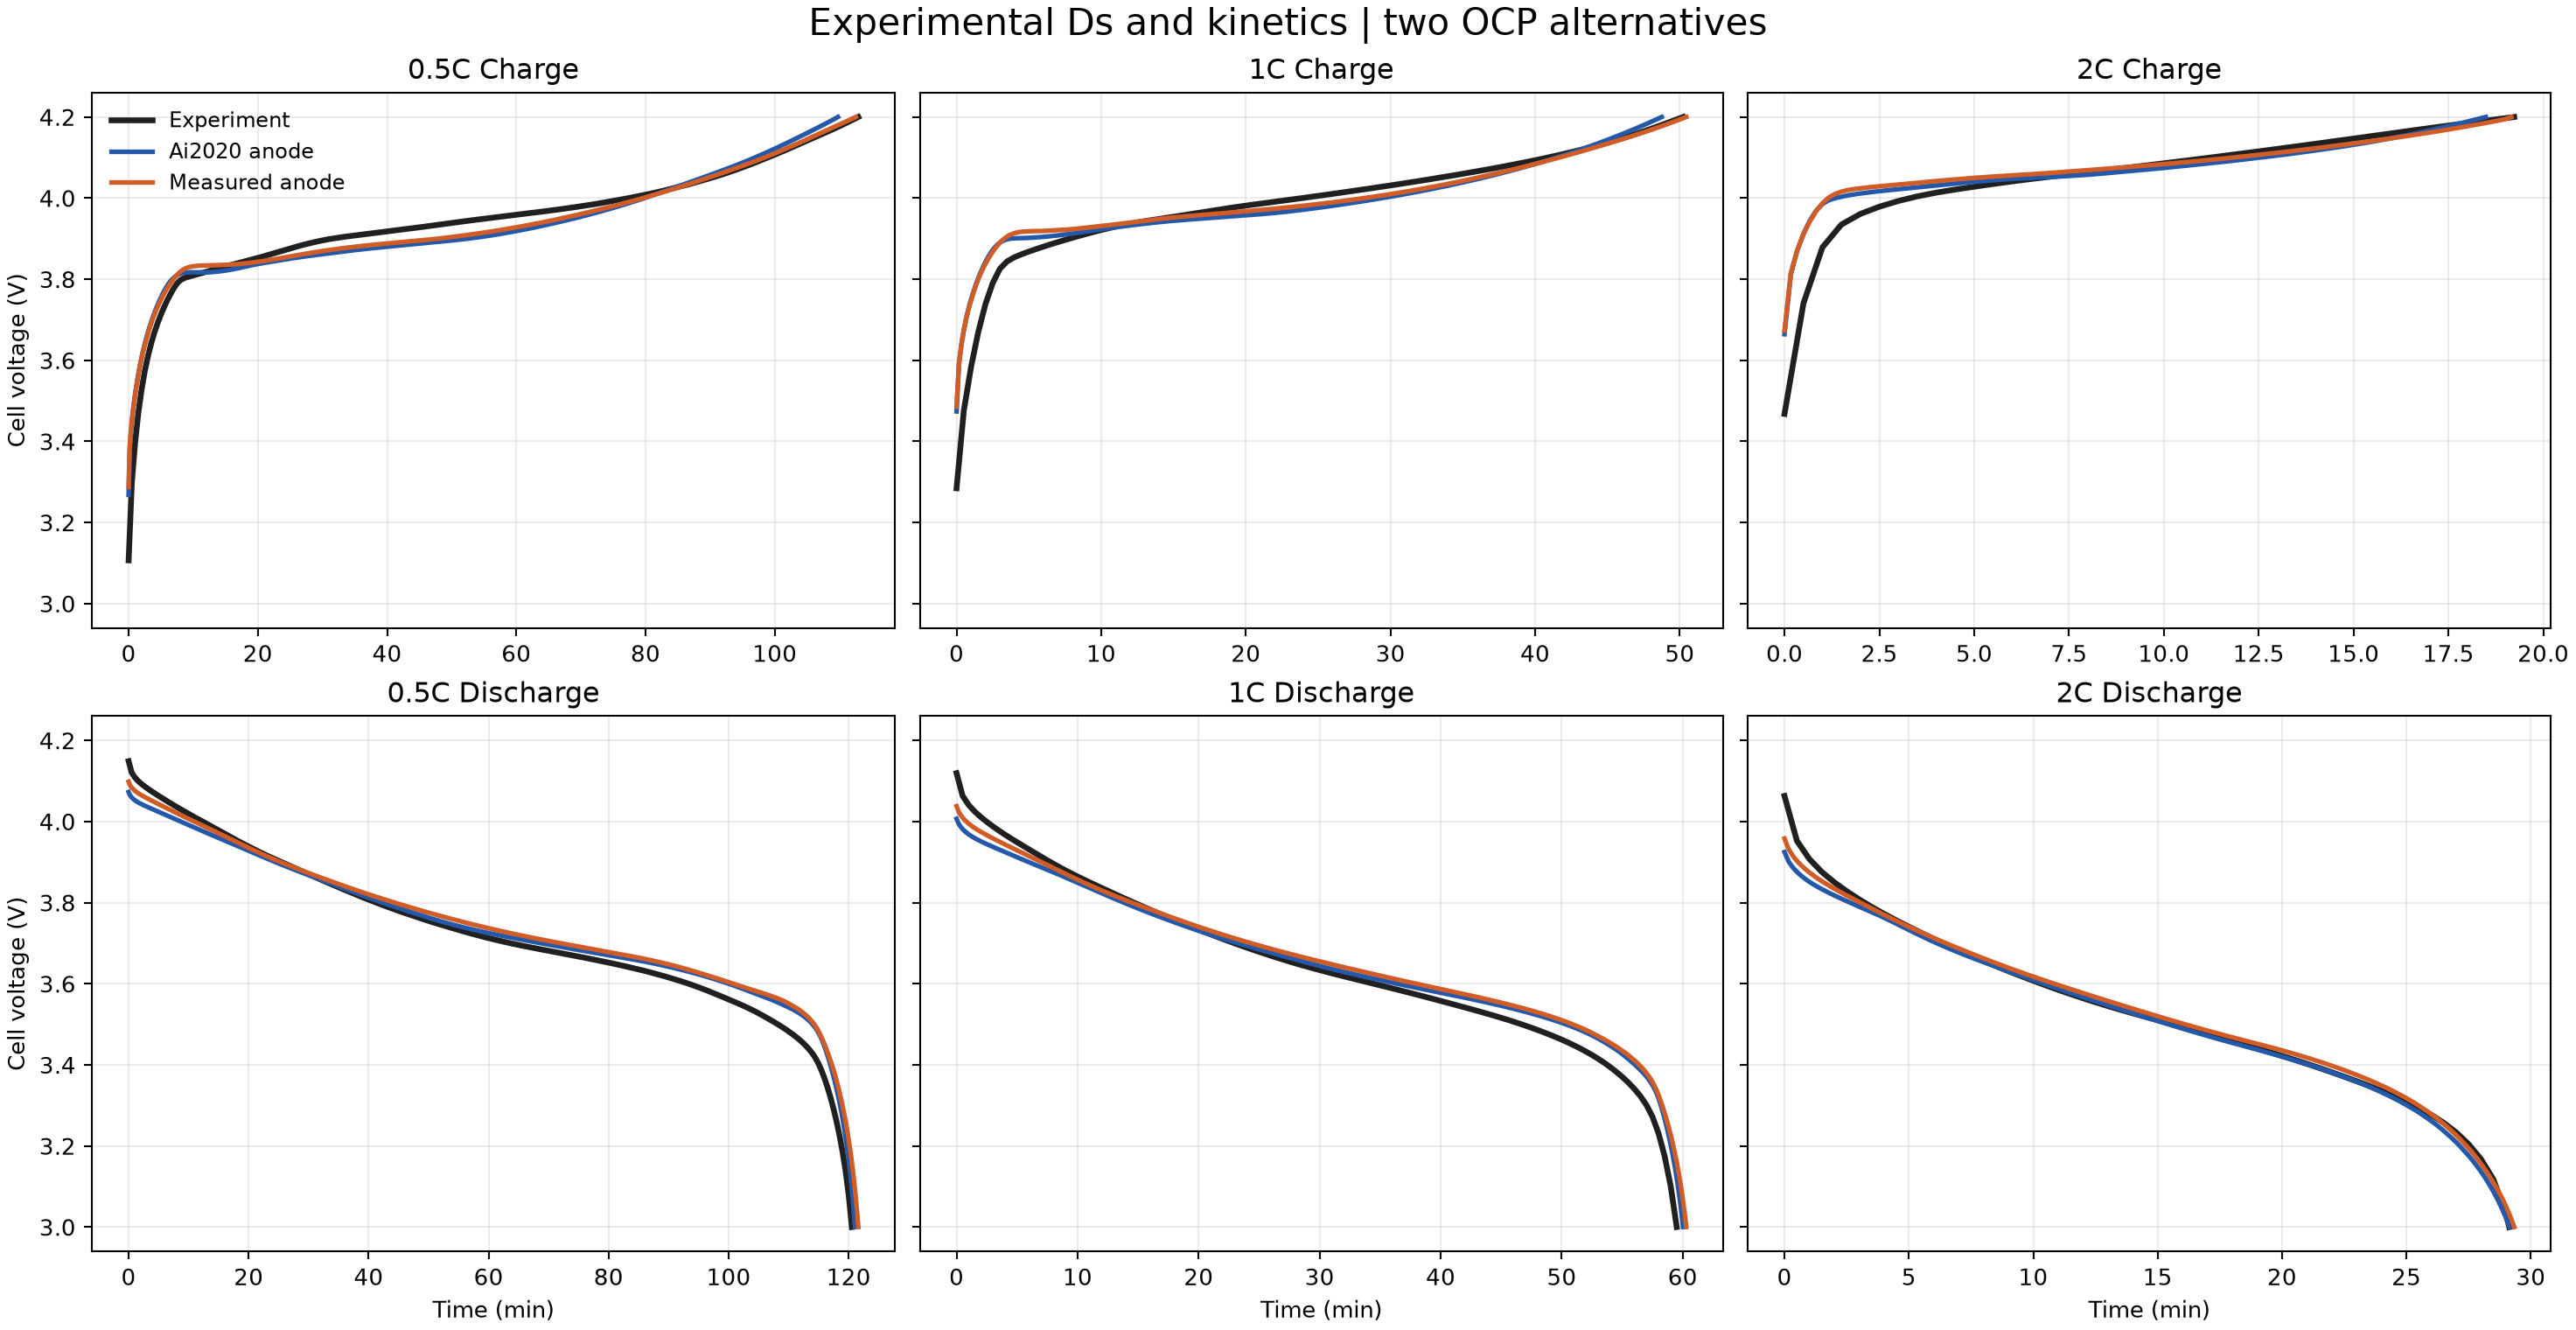

In [ ]:
from IPython.display import Image, display
display(Image(filename="Stage3_prefit_two_OCP_overlay_six_curves.png"))


### Ai2020 OCP 전해질 비교


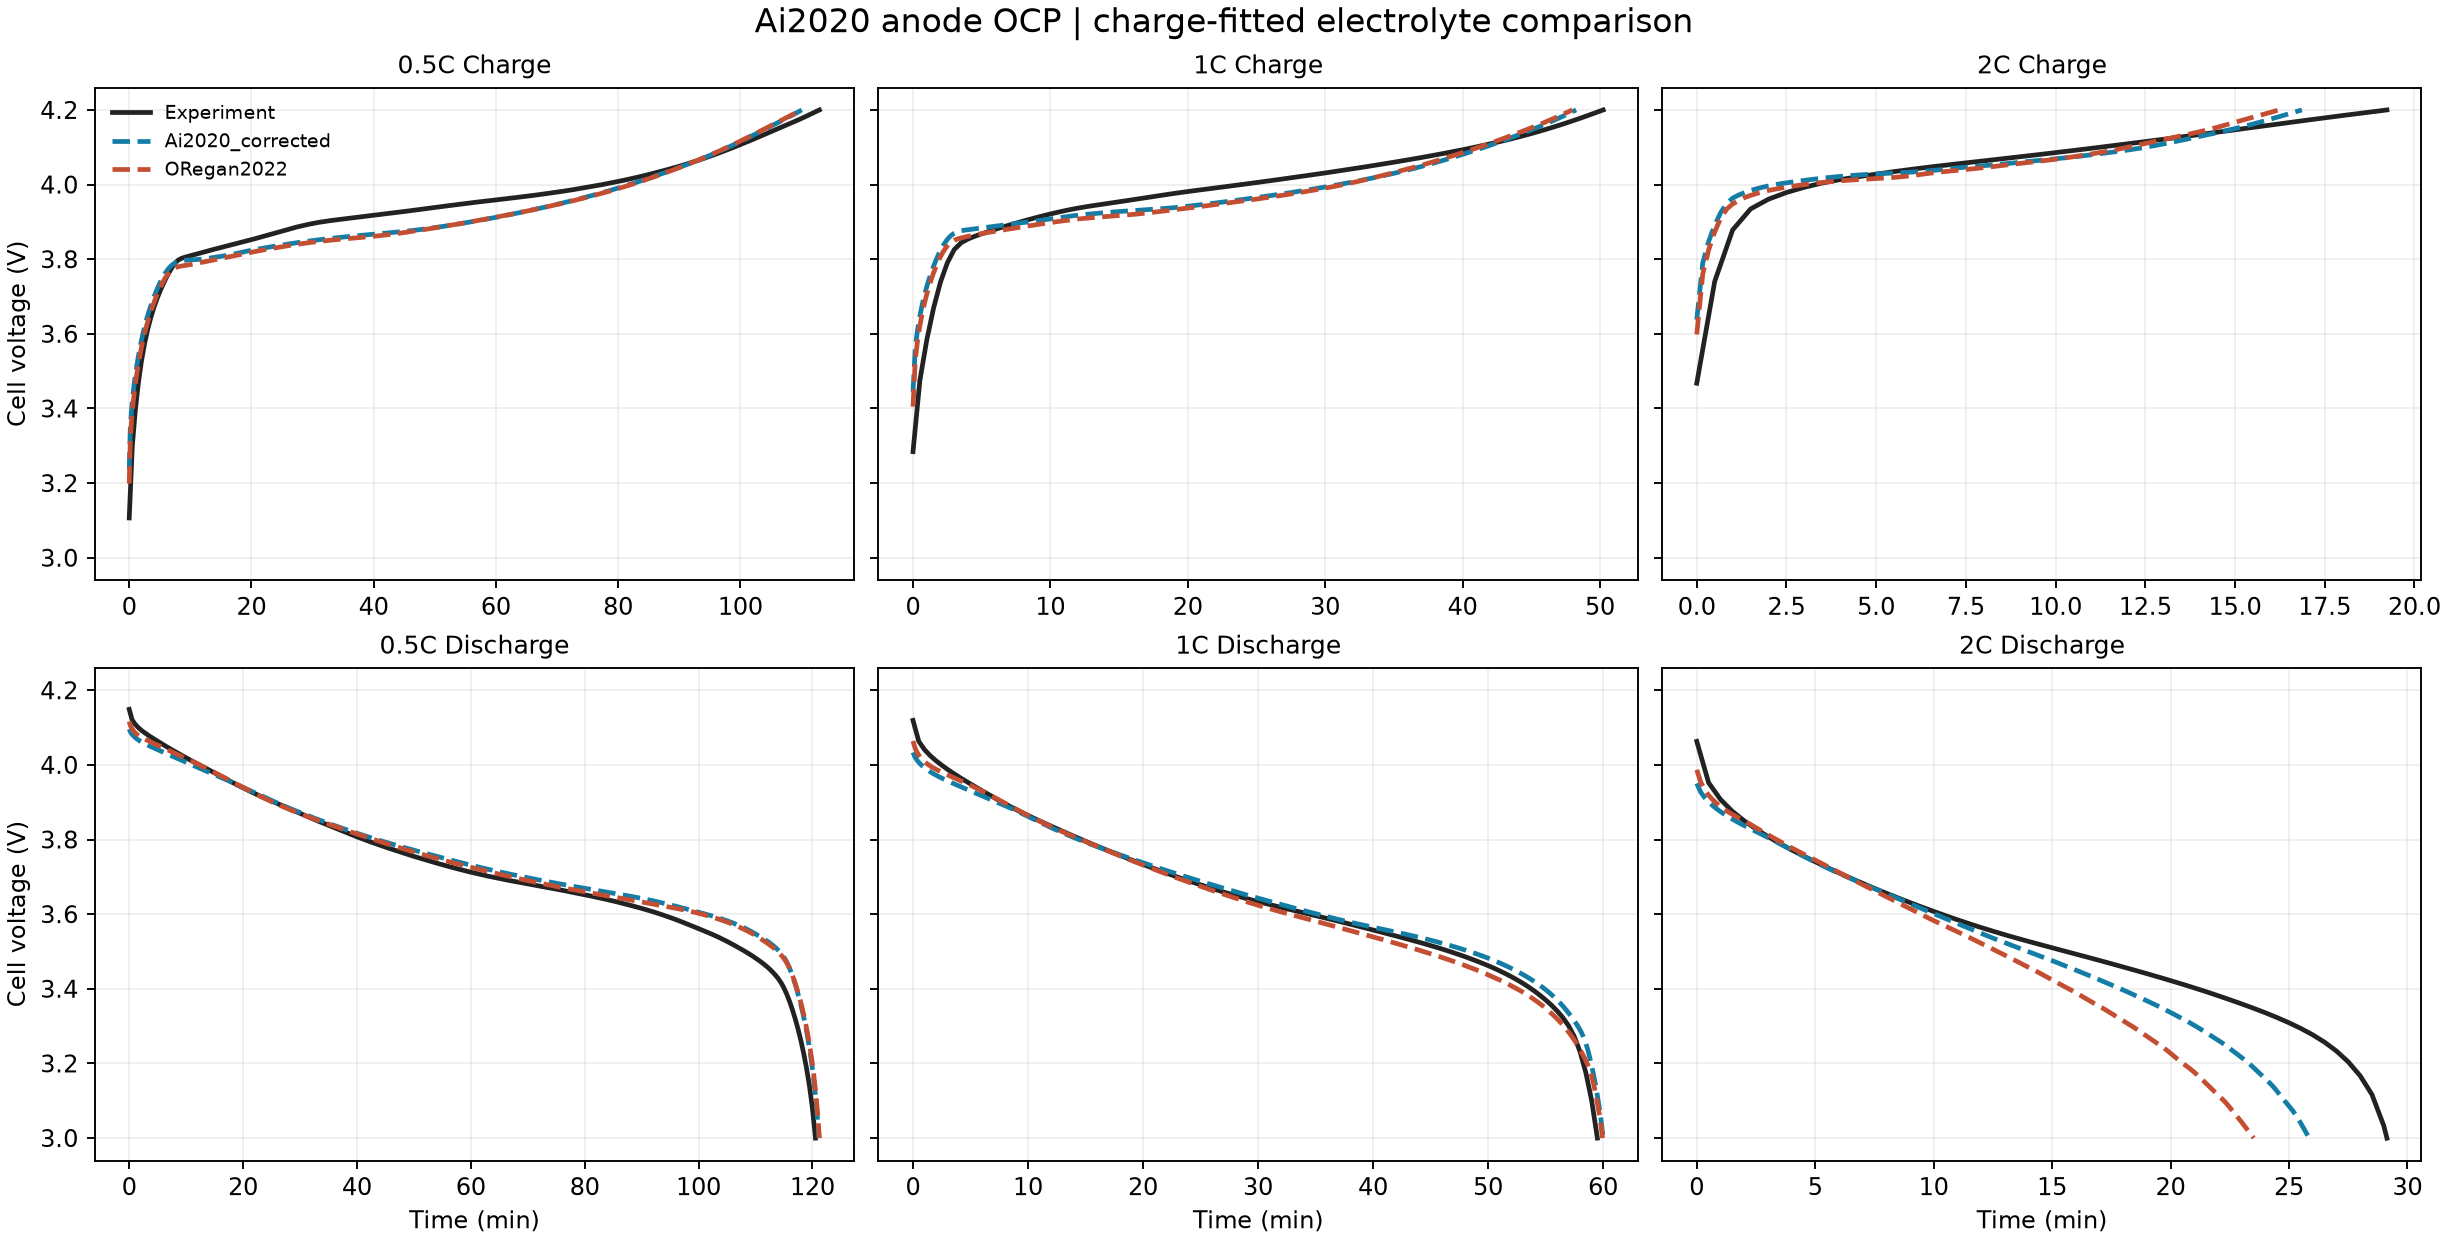

In [ ]:
from IPython.display import Image, display
display(Image(filename="Stage3_fit_Ai2020_anode__measured_cathode_electrolyte_comparison.png"))


### Measured OCP 전해질 비교


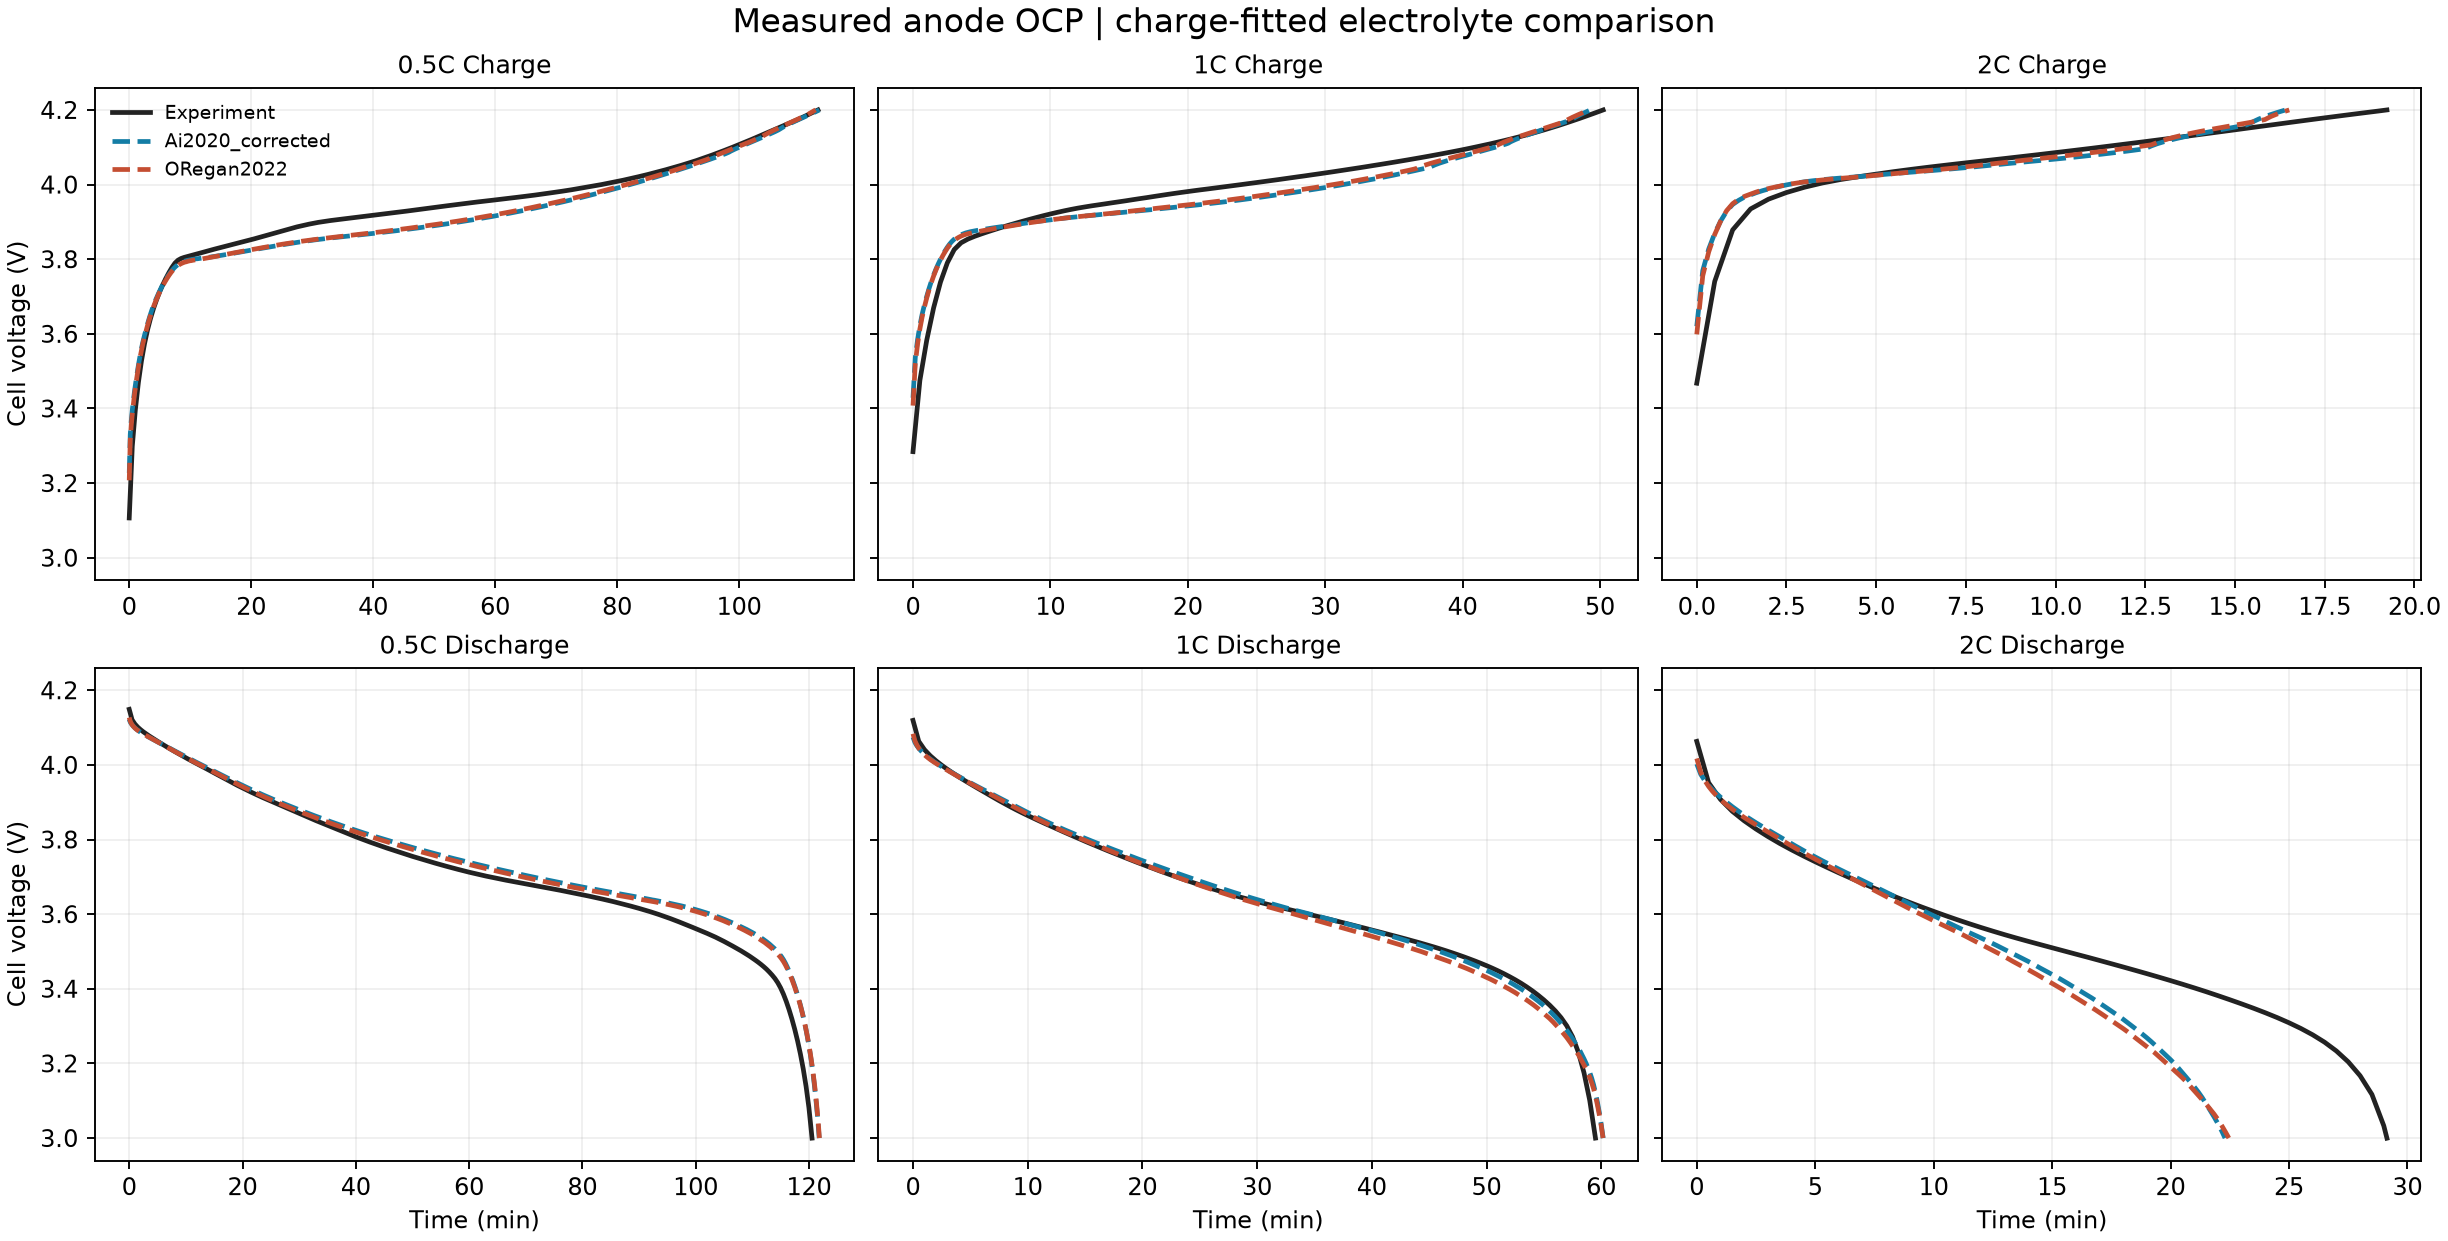

In [ ]:
from IPython.display import Image, display
display(Image(filename="Stage3_fit_measured_anode__measured_cathode_electrolyte_comparison.png"))


### ORegan2022 음극 전위


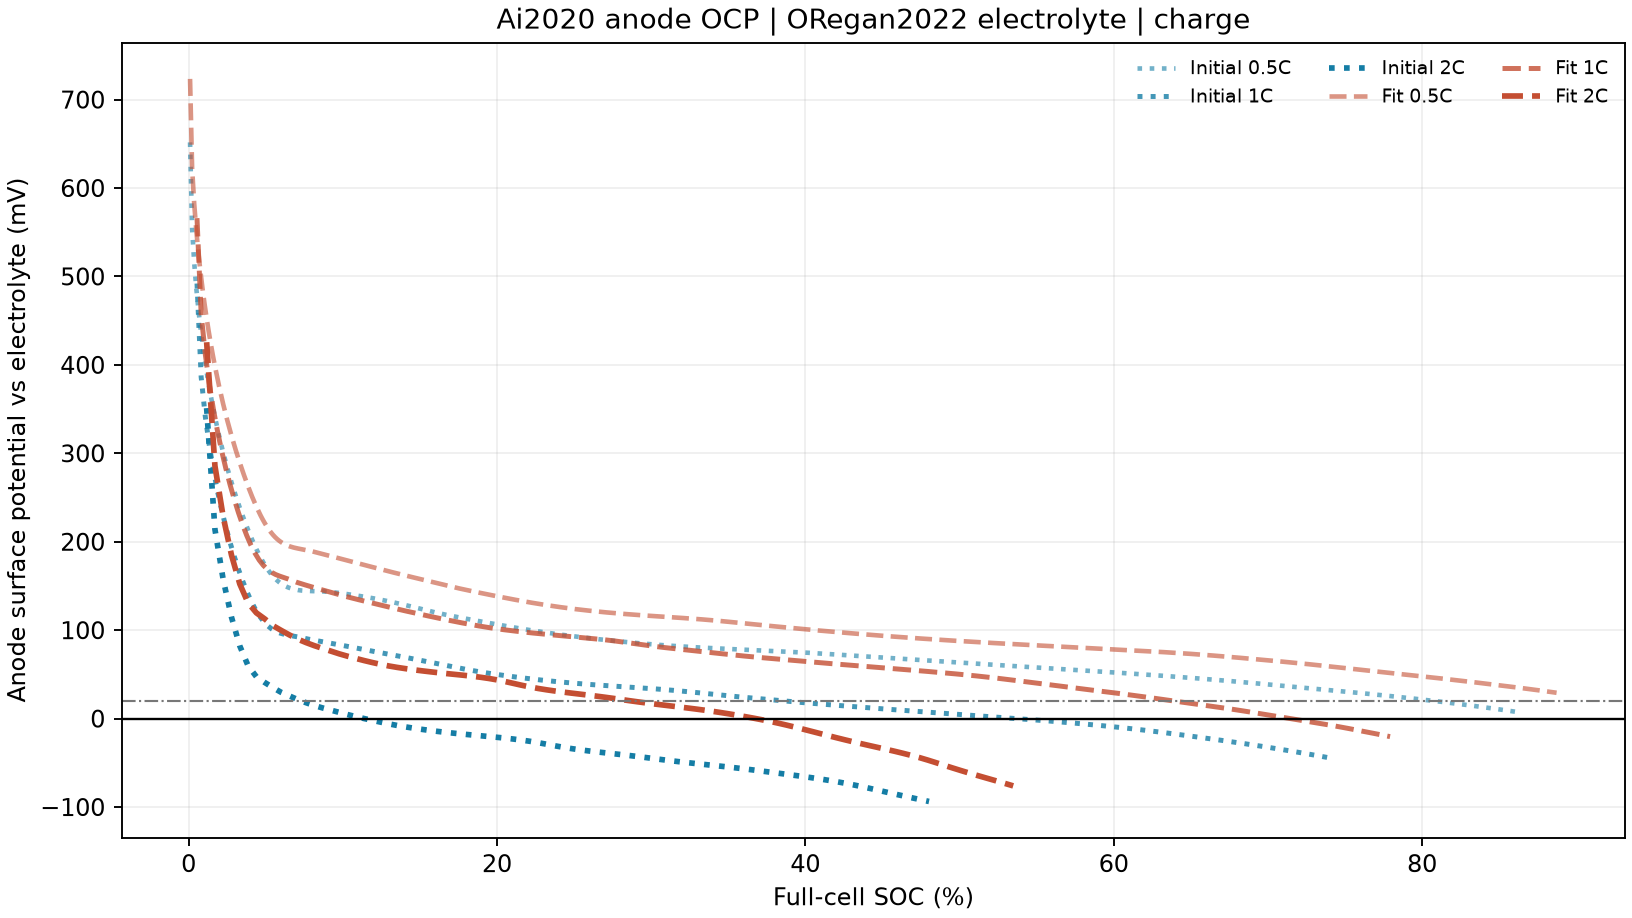

In [ ]:
from IPython.display import Image, display
display(Image(filename="Stage3_fit_Ai2020_anode__measured_cathode_ORegan2022_anode_potential.png"))
